# CS336 Lecture 2 — 录课版离线阅读

来源：[官方录课版](https://cs336.stanford.edu/lectures/?trace=lecture_02_recording)；[官方仓库](https://github.com/stanford-cs336/lectures)。获取日期：2026-10-21。

这是官方执行记录的阅读转换版，不是重新执行课件得到的结果。讲解、原始执行步骤、变量快照及图片按记录顺序保留。原始代码保存在 `lecture_02_recording_source.py`；当前仓库版本另外保存在 `lecture_02.py`，两者不要混用。

图片嵌入 Notebook，可离线显示；外部参考链接仍需网络。代码以文本展示，避免“运行全部”启动原课件的大内存/GPU实验。要修改运行示例，请打开旁边的 `lecture_02_practice.ipynb`。

**阅读顺序建议：** tensors_basics → tensors_memory → tensor_einops → gradients_basics；资源计算、roofline、checkpointing 可随后补。用编辑器 Notebook 大纲跳转。

录课中的口误或代码注释保留原样。例如原 `tensors_basics` 中标为 rank-3 的 `torch.zeros(4, 8)` 实际仍为二维；练习版给出正确三维例子。


## main

**记录步骤 1 · main · L16**

```python
def main():
```

**记录步骤 2 · main · L17**

```python
text("Announcements:")
```

Announcements:

**记录步骤 3 · main · L18**

```python
text("- Join the CS336 slack")
```

- Join the CS336 slack

**记录步骤 4 · main · L19**

```python
text("- Sign up on Modal with your **Stanford** email")
```

- Sign up on Modal with your **Stanford** email

**记录步骤 5 · main · L20**

```python
text("- Read the [AI policy guide](https://docs.google.com/document/d/1SZAlExB1qAc9izHt54gwunNpjKE6wXb8Y7yA_e-baK8/edit?tab=t.0)")
```

- Read the [AI policy guide](https://docs.google.com/document/d/1SZAlExB1qAc9izHt54gwunNpjKE6wXb8Y7yA_e-baK8/edit?tab=t.0)

**记录步骤 6 · main · L21**

```python
text("- Read the [cluster guide](https://docs.google.com/document/d/1cHE0iKVyXLJ3XpIs2XuXTmZ-HMmPk2hIPeCvy-AydMg/edit?tab=t.otis27tacaef)")
```

- Read the [cluster guide](https://docs.google.com/document/d/1cHE0iKVyXLJ3XpIs2XuXTmZ-HMmPk2hIPeCvy-AydMg/edit?tab=t.otis27tacaef)

**记录步骤 7 · main · L23**

```python
text("Marin 1e23 FLOPs run finished and [matched forecasts](https://x.com/WilliamBarrHeld/status/2039373983632814318)")
```

Marin 1e23 FLOPs run finished and [matched forecasts](https://x.com/WilliamBarrHeld/status/2039373983632814318)

**记录步骤 8 · main · L24**

```python
image("https://pbs.twimg.com/media/HE1P1HmaUAAjLXF?format=jpg&name=medium", width=700)
```

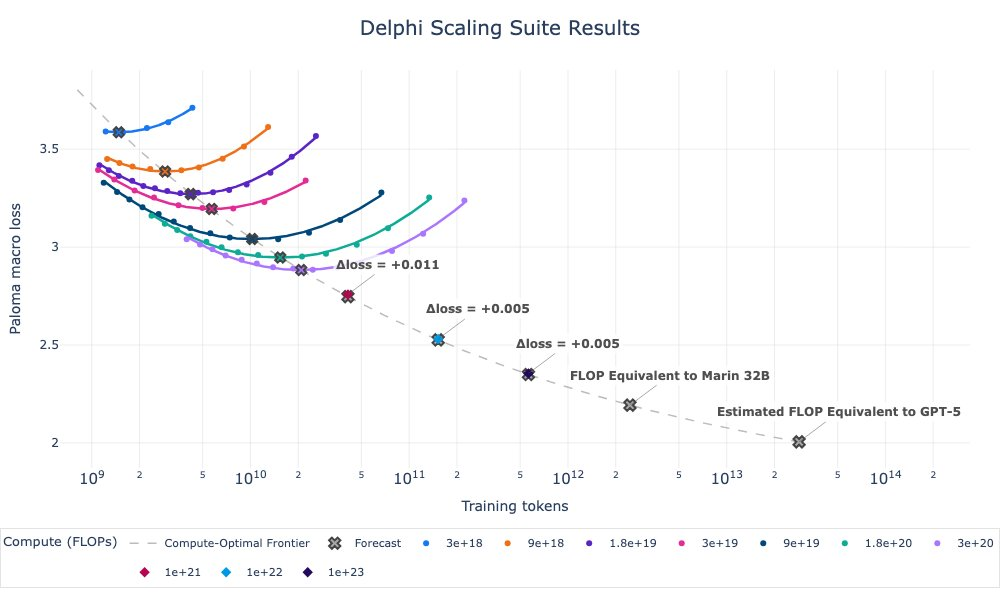

**记录步骤 9 · main · L26**

```python
text("Last lecture: overview, tokenization")
```

Last lecture: overview, tokenization

**记录步骤 10 · main · L27**

```python
text("Today: resource accounting (systems)")
```

Today: resource accounting (systems)

**记录步骤 11 · main · L29**

```python
text("Recall: what's the best model one can train given fixed resources (compute, memory)?")
```

Recall: what's the best model one can train given fixed resources (compute, memory)?

**记录步骤 12 · main · L30**

```python
text("In other words: maximize (computational) **efficiency**.")
```

In other words: maximize (computational) **efficiency**.

**记录步骤 13 · main · L31**

```python
text("Precursor: We need to understand the resources (compute, memory) for a given computation?")
```

Precursor: We need to understand the resources (compute, memory) for a given computation?

**记录步骤 14 · main · L33**

```python
motivating_questions()
```

## motivating_questions

**记录步骤 15 · motivating_questions · L71**

```python
def motivating_questions():
```

**记录步骤 16 · motivating_questions · L72**

```python
text("**Question**: How long would it take to train a 70B parameter model on 15T tokens on 1024 B100s?")
```

**Question**: How long would it take to train a 70B parameter model on 15T tokens on 1024 B100s?

**记录步骤 17 · motivating_questions · L73**

```python
total_flops = 6 * 70e9 * 15e12  # @inspect total_flops
```

原课堂变量快照：
```json
{
  "total_flops": {
    "type": "float",
    "contents": 6.3e+24,
    "dtype": null,
    "shape": null
  }
}
```

**记录步骤 18 · motivating_questions · L74**

```python
h100_flop_per_sec = 1979e12 / 2
```

**记录步骤 19 · motivating_questions · L75**

```python
mfu = 0.5
```

**记录步骤 20 · motivating_questions · L76**

```python
flops_per_day = h100_flop_per_sec * mfu * 1024 * 60 * 60 * 24  # @inspect flops_per_day
```

原课堂变量快照：
```json
{
  "flops_per_day": {
    "type": "float",
    "contents": 4.37723136e+22,
    "dtype": null,
    "shape": null
  }
}
```

**记录步骤 21 · motivating_questions · L77**

```python
days = total_flops / flops_per_day  # @inspect days
```

原课堂变量快照：
```json
{
  "days": {
    "type": "float",
    "contents": 143.92659381842682,
    "dtype": null,
    "shape": null
  }
}
```

**记录步骤 22 · motivating_questions · L79**

```python
text("**Question**: What's the largest model that can you can train on 8 H100s using AdamW (naively)?")
```

**Question**: What's the largest model that can you can train on 8 H100s using AdamW (naively)?

**记录步骤 23 · motivating_questions · L80**

```python
h100_bytes = 80e9  # @inspect h100_bytes
```

原课堂变量快照：
```json
{
  "h100_bytes": {
    "type": "float",
    "contents": 80000000000.0,
    "dtype": null,
    "shape": null
  }
}
```

**记录步骤 24 · motivating_questions · L81**

```python
bytes_per_parameter = 2 + 2 + (4 + 4)  # parameters, gradients, optimizer state  @inspect bytes_per_parameter
```

原课堂变量快照：
```json
{
  "bytes_per_parameter": {
    "type": "int",
    "contents": 12,
    "dtype": null,
    "shape": null
  }
}
```

**记录步骤 25 · motivating_questions · L82**

```python
num_parameters = (h100_bytes * 8) / bytes_per_parameter  # @inspect num_parameters
```

原课堂变量快照：
```json
{
  "num_parameters": {
    "type": "float",
    "contents": 53333333333.333336,
    "dtype": null,
    "shape": null
  }
}
```

**记录步骤 26 · motivating_questions · L83**

```python
text("Caveat: activations are not accounted for (depends on batch size and sequence length).")
```

Caveat: activations are not accounted for (depends on batch size and sequence length).

**记录步骤 27 · motivating_questions · L85**

```python
text("This is a rough back-of-the-envelope calculation.")
```

This is a rough back-of-the-envelope calculation.

## main

**记录步骤 28 · main · L33**

```python
motivating_questions()
```

**记录步骤 29 · main · L35**

```python
text("What knowledge to take away:")
```

What knowledge to take away:

**记录步骤 30 · main · L36**

```python
text("- Mechanics: straightforward (PyTorch semantics)")
```

- Mechanics: straightforward (PyTorch semantics)

**记录步骤 31 · main · L37**

```python
text("- Mindset: resource accounting (remember to do it)")
```

- Mindset: resource accounting (remember to do it)

**记录步骤 32 · main · L38**

```python
text("- Intuitions: get a sense of how resources are spent, no ML magic today")
```

- Intuitions: get a sense of how resources are spent, no ML magic today

**记录步骤 33 · main · L41**

```python
tensors_basics()
```

## tensors_basics

**记录步骤 34 · tensors_basics · L88**

```python
def tensors_basics():
```

**记录步骤 35 · tensors_basics · L89**

```python
text("Tensors are the basic building block for storing everything:")
```

Tensors are the basic building block for storing everything:

**记录步骤 36 · tensors_basics · L90**

```python
text("- parameters, gradients, optimizer state, data, activations.")
```

- parameters, gradients, optimizer state, data, activations.

**记录步骤 37 · tensors_basics · L92**

```python
text("Example: parameters of the DeepSeek v3.2 model "), link(deepseek_v3_2_2025)
```

Example: parameters of the DeepSeek v3.2 model 

[DeepSeek-V3.2: Pushing the Frontier of Open Large Language Models](https://arxiv.org/abs/2512.02556)

**记录步骤 38 · tensors_basics · L93**

```python
link(title="DeepSeek v3.2 model on Hugging Face", url="https://huggingface.co/deepseek-ai/DeepSeek-V3.2?show_file_info=model.safetensors.index.json")
```

[DeepSeek v3.2 model on Hugging Face](https://huggingface.co/deepseek-ai/DeepSeek-V3.2?show_file_info=model.safetensors.index.json)

**记录步骤 39 · tensors_basics · L95**

```python
x = torch.zeros(4)     # vector @inspect x
```

原课堂变量快照：
```json
{
  "x": {
    "type": "torch.Tensor",
    "contents": [
      0.0,
      0.0,
      0.0,
      0.0
    ],
    "dtype": "torch.float32",
    "shape": [
      4
    ]
  }
}
```

**记录步骤 40 · tensors_basics · L96**

```python
x = torch.zeros(4, 8)  # matrix @inspect x
```

原课堂变量快照：
```json
{
  "x": {
    "type": "torch.Tensor",
    "contents": [
      [
        0.0,
        0.0,
        0.0,
        0.0,
        0.0,
        0.0,
        0.0,
        0.0
      ],
      [
        0.0,
        0.0,
        0.0,
        0.0,
        0.0,
        0.0,
        0.0,
        0.0
      ],
      [
        0.0,
        0.0,
        0.0,
        0.0,
        0.0,
        0.0,
        0.0,
        0.0
      ],
      [
        0.0,
        0.0,
        0.0,
        0.0,
        0.0,
        0.0,
        0.0,
        0.0
      ]
    ],
    "dtype": "torch.float32",
    "shape": [
      4,
      8
    ]
  }
}
```

**记录步骤 41 · tensors_basics · L97**

```python
x = torch.zeros(4, 8)  # rank-3 tensor @inspect x
```

原课堂变量快照：
```json
{
  "x": {
    "type": "torch.Tensor",
    "contents": [
      [
        0.0,
        0.0,
        0.0,
        0.0,
        0.0,
        0.0,
        0.0,
        0.0
      ],
      [
        0.0,
        0.0,
        0.0,
        0.0,
        0.0,
        0.0,
        0.0,
        0.0
      ],
      [
        0.0,
        0.0,
        0.0,
        0.0,
        0.0,
        0.0,
        0.0,
        0.0
      ],
      [
        0.0,
        0.0,
        0.0,
        0.0,
        0.0,
        0.0,
        0.0,
        0.0
      ]
    ],
    "dtype": "torch.float32",
    "shape": [
      4,
      8
    ]
  }
}
```

## main

**记录步骤 42 · main · L41**

```python
tensors_basics()
```

**记录步骤 43 · main · L42**

```python
tensors_memory()
```

## tensors_memory

**记录步骤 44 · tensors_memory · L100**

```python
def tensors_memory():
```

**记录步骤 45 · tensors_memory · L101**

```python
text("Almost everything (parameters, gradients, activations, optimizer states) are stored as floating point numbers.")
```

Almost everything (parameters, gradients, activations, optimizer states) are stored as floating point numbers.

**记录步骤 46 · tensors_memory · L103**

```python
text("## float32")
```

## float32

**记录步骤 47 · tensors_memory · L104**

```python
link(title="Wikipedia", url="https://en.wikipedia.org/wiki/Single-precision_floating-point_format")
```

[Wikipedia](https://en.wikipedia.org/wiki/Single-precision_floating-point_format)

**记录步骤 48 · tensors_memory · L105**

```python
image("images/fp32.png", width=600)
```

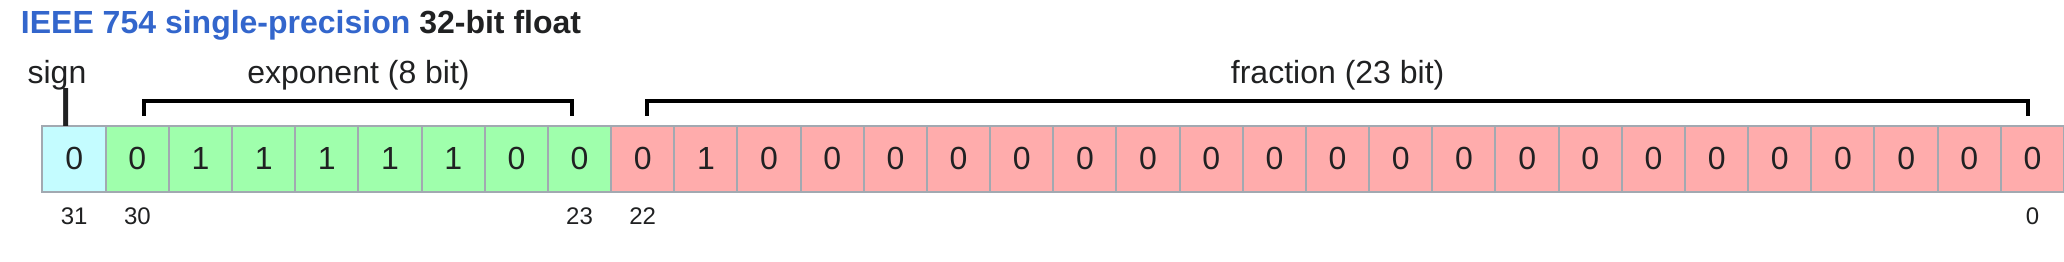

**记录步骤 49 · tensors_memory · L106**

```python
text("The float32 data type (also known as fp32 or single precision) is the default.")
```

The float32 data type (also known as fp32 or single precision) is the default.

**记录步骤 50 · tensors_memory · L107**

```python
text("Traditionally, in scientific computing, float32 is the baseline; you could use double precision (float64) in some cases.")
```

Traditionally, in scientific computing, float32 is the baseline; you could use double precision (float64) in some cases.

**记录步骤 51 · tensors_memory · L108**

```python
text("In deep learning, you can be a lot sloppier.")
```

In deep learning, you can be a lot sloppier.

**记录步骤 52 · tensors_memory · L110**

```python
text("Let's examine memory usage of these tensors.")
```

Let's examine memory usage of these tensors.

**记录步骤 53 · tensors_memory · L111**

```python
text("Memory is determined by the (i) number of values and (ii) data type of each value.")
```

Memory is determined by the (i) number of values and (ii) data type of each value.

**记录步骤 54 · tensors_memory · L112**

```python
x = torch.zeros(4, 8)  # @inspect x
```

原课堂变量快照：
```json
{
  "x": {
    "type": "torch.Tensor",
    "contents": [
      [
        0.0,
        0.0,
        0.0,
        0.0,
        0.0,
        0.0,
        0.0,
        0.0
      ],
      [
        0.0,
        0.0,
        0.0,
        0.0,
        0.0,
        0.0,
        0.0,
        0.0
      ],
      [
        0.0,
        0.0,
        0.0,
        0.0,
        0.0,
        0.0,
        0.0,
        0.0
      ],
      [
        0.0,
        0.0,
        0.0,
        0.0,
        0.0,
        0.0,
        0.0,
        0.0
      ]
    ],
    "dtype": "torch.float32",
    "shape": [
      4,
      8
    ]
  }
}
```

**记录步骤 55 · tensors_memory · L113**

```python
assert x.dtype == torch.float32  # Default type
```

**记录步骤 56 · tensors_memory · L114**

```python
assert x.numel() == 4 * 8
```

**记录步骤 57 · tensors_memory · L115**

```python
assert x.element_size() == 4  # Float is 4 bytes
```

**记录步骤 58 · tensors_memory · L116**

```python
assert get_memory_usage(x) == 4 * 8 * 4  # 128 bytes
```

**记录步骤 59 · get_memory_usage · L818**

```python
def get_memory_usage(x: torch.Tensor):
```

**记录步骤 60 · get_memory_usage · L819**

```python
return x.numel() * x.element_size()
```

**记录步骤 61 · tensors_memory · L116**

```python
assert get_memory_usage(x) == 4 * 8 * 4  # 128 bytes
```

**记录步骤 62 · tensors_memory · L118**

```python
text("One matrix in the feedforward layer of GPT-3:")
```

One matrix in the feedforward layer of GPT-3:

**记录步骤 63 · tensors_memory · L119**

```python
assert get_memory_usage(torch.empty(12288 * 4, 12288)) == 2304 * 1024 * 1024  # 2.3 GB @stepover
```

**记录步骤 64 · tensors_memory · L121**

```python
text("## float16")
```

## float16

**记录步骤 65 · tensors_memory · L122**

```python
link(title="Wikipedia", url="https://en.wikipedia.org/wiki/Half-precision_floating-point_format")
```

[Wikipedia](https://en.wikipedia.org/wiki/Half-precision_floating-point_format)

**记录步骤 66 · tensors_memory · L123**

```python
image("images/fp16.png", width=400)
```

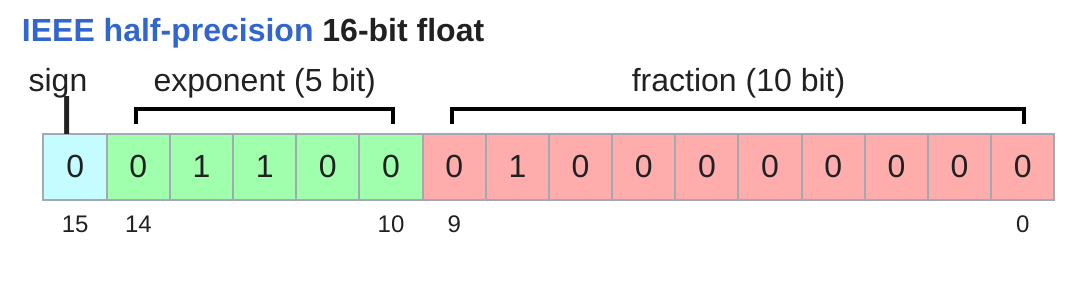

**记录步骤 67 · tensors_memory · L124**

```python
text("The float16 data type (also known as fp16 or half precision) cuts down the memory.")
```

The float16 data type (also known as fp16 or half precision) cuts down the memory.

**记录步骤 68 · tensors_memory · L125**

```python
x = torch.zeros(4, 8, dtype=torch.float16)  # @inspect x
```

原课堂变量快照：
```json
{
  "x": {
    "type": "torch.Tensor",
    "contents": [
      [
        0.0,
        0.0,
        0.0,
        0.0,
        0.0,
        0.0,
        0.0,
        0.0
      ],
      [
        0.0,
        0.0,
        0.0,
        0.0,
        0.0,
        0.0,
        0.0,
        0.0
      ],
      [
        0.0,
        0.0,
        0.0,
        0.0,
        0.0,
        0.0,
        0.0,
        0.0
      ],
      [
        0.0,
        0.0,
        0.0,
        0.0,
        0.0,
        0.0,
        0.0,
        0.0
      ]
    ],
    "dtype": "torch.float16",
    "shape": [
      4,
      8
    ]
  }
}
```

**记录步骤 69 · tensors_memory · L126**

```python
assert x.element_size() == 2
```

**记录步骤 70 · tensors_memory · L127**

```python
text("However, the dynamic range (especially for small numbers) isn't great.")
```

However, the dynamic range (especially for small numbers) isn't great.

**记录步骤 71 · tensors_memory · L128**

```python
x = torch.tensor([1e-8], dtype=torch.float16)  # @inspect x
```

原课堂变量快照：
```json
{
  "x": {
    "type": "torch.Tensor",
    "contents": [
      0.0
    ],
    "dtype": "torch.float16",
    "shape": [
      1
    ]
  }
}
```

**记录步骤 72 · tensors_memory · L129**

```python
assert x == 0  # Underflow!
```

**记录步骤 73 · tensors_memory · L130**

```python
text("If this happens when you train, you can get instability.")
```

If this happens when you train, you can get instability.

**记录步骤 74 · tensors_memory · L132**

```python
text("## bfloat16")
```

## bfloat16

**记录步骤 75 · tensors_memory · L133**

```python
link(title="Wikipedia", url="https://en.wikipedia.org/wiki/Bfloat16_floating-point_format")
```

[Wikipedia](https://en.wikipedia.org/wiki/Bfloat16_floating-point_format)

**记录步骤 76 · tensors_memory · L134**

```python
image("images/bf16.png", width=400)
```

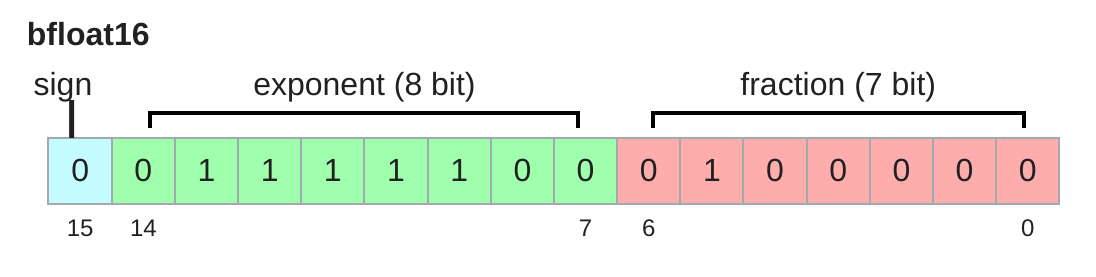

**记录步骤 77 · tensors_memory · L135**

```python
text("Google Brain developed bfloat (brain floating point) in 2018 to address this issue.")
```

Google Brain developed bfloat (brain floating point) in 2018 to address this issue.

**记录步骤 78 · tensors_memory · L136**

```python
text("bfloat16 uses the same memory as float16 but has the same dynamic range as float32!")
```

bfloat16 uses the same memory as float16 but has the same dynamic range as float32!

**记录步骤 79 · tensors_memory · L137**

```python
text("The only catch is that the resolution is worse, but this matters less for deep learning.")
```

The only catch is that the resolution is worse, but this matters less for deep learning.

**记录步骤 80 · tensors_memory · L138**

```python
x = torch.tensor([1e-8], dtype=torch.bfloat16)  # @inspect x
```

原课堂变量快照：
```json
{
  "x": {
    "type": "torch.Tensor",
    "contents": [
      1.0011717677116394e-08
    ],
    "dtype": "torch.bfloat16",
    "shape": [
      1
    ]
  }
}
```

**记录步骤 81 · tensors_memory · L139**

```python
assert x != 0  # No underflow!
```

**记录步骤 82 · tensors_memory · L141**

```python
text("Implications on training:")
```

Implications on training:

**记录步骤 83 · tensors_memory · L142**

```python
text("- Training with float32 works, but requires lots of memory.")
```

- Training with float32 works, but requires lots of memory.

**记录步骤 84 · tensors_memory · L143**

```python
text("- Training with fp8, float16 and even bfloat16 is risky, and you can get instability.")
```

- Training with fp8, float16 and even bfloat16 is risky, and you can get instability.

**记录步骤 85 · tensors_memory · L145**

```python
text("Mixed precision training "), link("https://arxiv.org/pdf/1710.03740.pdf")
```

Mixed precision training 

[Mixed Precision Training](https://arxiv.org/pdf/1710.03740.pdf)

**记录步骤 86 · tensors_memory · L146**

```python
text("- Use bf16 for parameters, activations, and gradients")
```

- Use bf16 for parameters, activations, and gradients

**记录步骤 87 · tensors_memory · L147**

```python
text("- Use fp32 for optimizer states")
```

- Use fp32 for optimizer states

**记录步骤 88 · tensors_memory · L149**

```python
text("Pytorch has an automatic mixed precision (AMP) library. "), link(title="docs", url="https://pytorch.org/docs/stable/amp.html")
```

Pytorch has an automatic mixed precision (AMP) library. 

[docs](https://pytorch.org/docs/stable/amp.html)

**记录步骤 89 · tensors_memory · L150**

```python
text("Tries to cast things into bf16 when safe (matmuls, not exp).")
```

Tries to cast things into bf16 when safe (matmuls, not exp).

**记录步骤 90 · tensors_memory · L152**

```python
text("## fp8")
```

## fp8

**记录步骤 91 · tensors_memory · L153**

```python
text("In 2022, fp8 was standardized, motivated by machine learning workloads [primer](https://docs.nvidia.com/deeplearning/transformer-engine/user-guide/examples/fp8_primer.html).")
```

In 2022, fp8 was standardized, motivated by machine learning workloads [primer](https://docs.nvidia.com/deeplearning/transformer-engine/user-guide/examples/fp8_primer.html).

**记录步骤 92 · tensors_memory · L154**

```python
image("https://docs.nvidia.com/deeplearning/transformer-engine/user-guide/_images/fp8_formats.png", width=400)
```

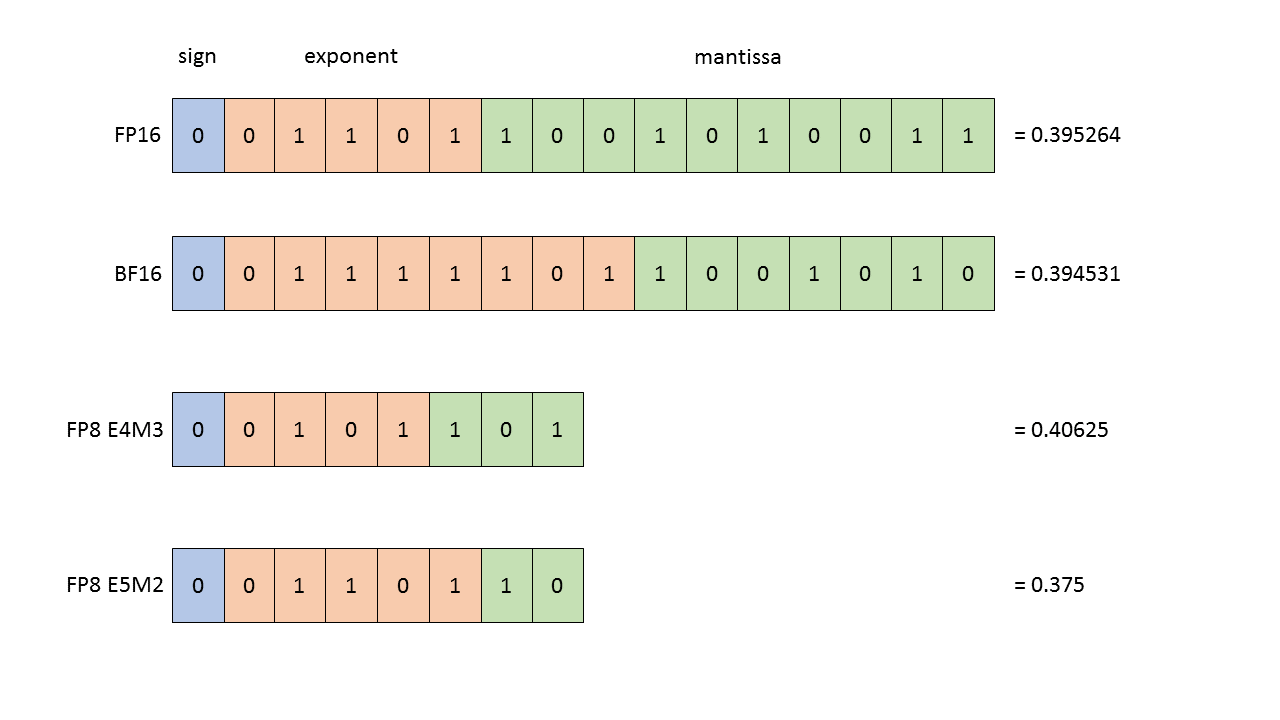

**记录步骤 93 · tensors_memory · L155**

```python
text("H100s support two variants of FP8: E4M3 (range [-448, 448]) and E5M2 ([-57344, 57344]).")
```

H100s support two variants of FP8: E4M3 (range [-448, 448]) and E5M2 ([-57344, 57344]).

**记录步骤 94 · tensors_memory · L156**

```python
text("Reference: "), link("https://arxiv.org/pdf/2209.05433.pdf")
```

Reference: 

[FP8 Formats for Deep Learning](https://arxiv.org/pdf/2209.05433.pdf)

**记录步骤 95 · tensors_memory · L158**

```python
text("## fp4")
```

## fp4

**记录步骤 96 · tensors_memory · L159**

```python
text("In 2025, NVIDIA developed [nvfp4](https://developer.nvidia.com/blog/introducing-nvfp4-for-efficient-and-accurate-low-precision-inference/)")
```

In 2025, NVIDIA developed [nvfp4](https://developer.nvidia.com/blog/introducing-nvfp4-for-efficient-and-accurate-low-precision-inference/)

**记录步骤 97 · tensors_memory · L160**

```python
text("Only 4 bits per value!")
```

Only 4 bits per value!

**记录步骤 98 · tensors_memory · L161**

```python
text("Values: -6, -4, -3, -2, -1.5, -1.0, -0.5, 0.0, 0.5, 1.0, 1.5, 2, 3, 4, 6")
```

Values: -6, -4, -3, -2, -1.5, -1.0, -0.5, 0.0, 0.5, 1.0, 1.5, 2, 3, 4, 6

**记录步骤 99 · tensors_memory · L162**

```python
text("Use a separate scale factor per block")
```

Use a separate scale factor per block

**记录步骤 100 · tensors_memory · L163**

```python
text("Nemotron 3 Super was trained in NVFP4 "), link(nemotron_3_2025)
```

Nemotron 3 Super was trained in NVFP4 

[NVIDIA Nemotron 3: Efficient and Open Intelligence](https://arxiv.org/abs/2512.20856)

**记录步骤 101 · tensors_memory · L165**

```python
text("Some of this is done in NVIDIA libraries outside of user control.")
```

Some of this is done in NVIDIA libraries outside of user control.

## main

**记录步骤 102 · main · L42**

```python
tensors_memory()
```

**记录步骤 103 · main · L43**

```python
tensors_on_gpus()
```

## tensors_on_gpus

**记录步骤 104 · tensors_on_gpus · L168**

```python
def tensors_on_gpus():
```

**记录步骤 105 · tensors_on_gpus · L169**

```python
text("By default, tensors are stored in CPU memory.")
```

By default, tensors are stored in CPU memory.

**记录步骤 106 · tensors_on_gpus · L170**

```python
x = torch.zeros(32, 32)
```

**记录步骤 107 · tensors_on_gpus · L171**

```python
assert x.device == torch.device("cpu")
```

**记录步骤 108 · tensors_on_gpus · L173**

```python
text("However, in order to take advantage of the massive parallelism of GPUs, we need to move them to GPU memory.")
```

However, in order to take advantage of the massive parallelism of GPUs, we need to move them to GPU memory.

**记录步骤 109 · tensors_on_gpus · L174**

```python
image("images/cpu-gpu.png", width=600)
```

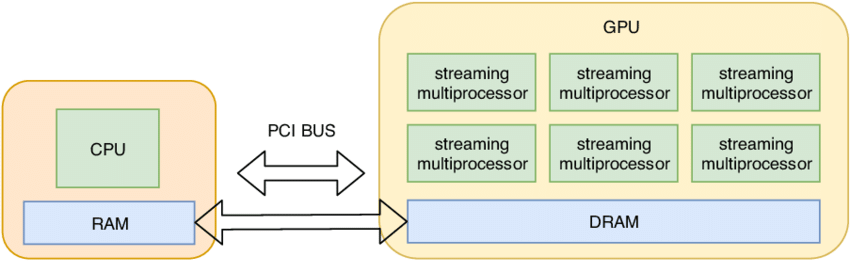

**记录步骤 110 · tensors_on_gpus · L176**

```python
text("Let's first see if we have any GPUs.")
```

Let's first see if we have any GPUs.

**记录步骤 111 · tensors_on_gpus · L177**

```python
if not torch.cuda.is_available():
```

**记录步骤 112 · tensors_on_gpus · L178**

```python
return
```

## main

**记录步骤 113 · main · L43**

```python
tensors_on_gpus()
```

**记录步骤 114 · main · L46**

```python
tensor_einops()
```

## tensor_einops

**记录步骤 115 · tensor_einops · L199**

```python
def tensor_einops():
```

**记录步骤 116 · tensor_einops · L200**

```python
einops_motivation()
```

**记录步骤 117 · einops_motivation · L211**

```python
def einops_motivation():
```

**记录步骤 118 · einops_motivation · L212**

```python
text("Easy to mess up the dimensions (what is -2, -1?)...")
```

Easy to mess up the dimensions (what is -2, -1?)...

**记录步骤 119 · einops_motivation · L213**

```python
text("Traditional PyTorch code:")
```

Traditional PyTorch code:

**记录步骤 120 · einops_motivation · L214**

```python
x = torch.ones(2, 2, 3)      # batch seq hidden  @inspect x
```

原课堂变量快照：
```json
{
  "x": {
    "type": "torch.Tensor",
    "contents": [
      [
        [
          1.0,
          1.0,
          1.0
        ],
        [
          1.0,
          1.0,
          1.0
        ]
      ],
      [
        [
          1.0,
          1.0,
          1.0
        ],
        [
          1.0,
          1.0,
          1.0
        ]
      ]
    ],
    "dtype": "torch.float32",
    "shape": [
      2,
      2,
      3
    ]
  }
}
```

**记录步骤 121 · einops_motivation · L215**

```python
y = torch.ones(2, 2, 3)      # batch seq hidden  @inspect y
```

原课堂变量快照：
```json
{
  "y": {
    "type": "torch.Tensor",
    "contents": [
      [
        [
          1.0,
          1.0,
          1.0
        ],
        [
          1.0,
          1.0,
          1.0
        ]
      ],
      [
        [
          1.0,
          1.0,
          1.0
        ],
        [
          1.0,
          1.0,
          1.0
        ]
      ]
    ],
    "dtype": "torch.float32",
    "shape": [
      2,
      2,
      3
    ]
  }
}
```

**记录步骤 122 · einops_motivation · L216**

```python
z = x @ y.transpose(-2, -1)  # batch seq seq  @inspect z
```

原课堂变量快照：
```json
{
  "z": {
    "type": "torch.Tensor",
    "contents": [
      [
        [
          3.0,
          3.0
        ],
        [
          3.0,
          3.0
        ]
      ],
      [
        [
          3.0,
          3.0
        ],
        [
          3.0,
          3.0
        ]
      ]
    ],
    "dtype": "torch.float32",
    "shape": [
      2,
      2,
      2
    ]
  }
}
```

**记录步骤 123 · einops_motivation · L217**

```python
text("Easy to mess up the dimensions (what is -2, -1?)...")
```

Easy to mess up the dimensions (what is -2, -1?)...

**记录步骤 124 · tensor_einops · L200**

```python
einops_motivation()
```

**记录步骤 125 · tensor_einops · L202**

```python
text("Einops is a library for manipulating tensors where dimensions are named.")
```

Einops is a library for manipulating tensors where dimensions are named.

**记录步骤 126 · tensor_einops · L203**

```python
text("It is inspired by Einstein summation notation (Einstein, 1916).")
```

It is inspired by Einstein summation notation (Einstein, 1916).

**记录步骤 127 · tensor_einops · L204**

```python
link(title="Einops tutorial", url="https://einops.rocks/1-einops-basics/")
```

[Einops tutorial](https://einops.rocks/1-einops-basics/)

**记录步骤 128 · tensor_einops · L206**

```python
einops_einsum()
```

**记录步骤 129 · einops_einsum · L220**

```python
def einops_einsum():
```

**记录步骤 130 · einops_einsum · L221**

```python
text("Einsum is generalized matrix multiplication with good bookkeeping.")
```

Einsum is generalized matrix multiplication with good bookkeeping.

**记录步骤 131 · einops_einsum · L223**

```python
x = torch.ones(3, 4)  # seq1 hidden @inspect x
```

原课堂变量快照：
```json
{
  "x": {
    "type": "torch.Tensor",
    "contents": [
      [
        1.0,
        1.0,
        1.0,
        1.0
      ],
      [
        1.0,
        1.0,
        1.0,
        1.0
      ],
      [
        1.0,
        1.0,
        1.0,
        1.0
      ]
    ],
    "dtype": "torch.float32",
    "shape": [
      3,
      4
    ]
  }
}
```

**记录步骤 132 · einops_einsum · L224**

```python
y = torch.ones(4, 3)  # hidden seq2 @inspect y
```

原课堂变量快照：
```json
{
  "y": {
    "type": "torch.Tensor",
    "contents": [
      [
        1.0,
        1.0,
        1.0
      ],
      [
        1.0,
        1.0,
        1.0
      ],
      [
        1.0,
        1.0,
        1.0
      ],
      [
        1.0,
        1.0,
        1.0
      ]
    ],
    "dtype": "torch.float32",
    "shape": [
      4,
      3
    ]
  }
}
```

**记录步骤 133 · einops_einsum · L227**

```python
z = x @ y   # seq1 seq2  @inspect z
```

原课堂变量快照：
```json
{
  "z": {
    "type": "torch.Tensor",
    "contents": [
      [
        4.0,
        4.0,
        4.0
      ],
      [
        4.0,
        4.0,
        4.0
      ],
      [
        4.0,
        4.0,
        4.0
      ]
    ],
    "dtype": "torch.float32",
    "shape": [
      3,
      3
    ]
  }
}
```

**记录步骤 134 · einops_einsum · L230**

```python
z = einsum(x, y, "seq1 hidden, hidden seq2 -> seq1 seq2")  # @inspect z
```

原课堂变量快照：
```json
{
  "z": {
    "type": "torch.Tensor",
    "contents": [
      [
        4.0,
        4.0,
        4.0
      ],
      [
        4.0,
        4.0,
        4.0
      ],
      [
        4.0,
        4.0,
        4.0
      ]
    ],
    "dtype": "torch.float32",
    "shape": [
      3,
      3
    ]
  }
}
```

**记录步骤 135 · einops_einsum · L232**

```python
text("Let's try a more complex example...")  # @clear x y z
```

原课堂变量快照：
```json
{
  "x": null,
  "y": null,
  "z": null
}
```

Let's try a more complex example...

**记录步骤 136 · einops_einsum · L234**

```python
x = torch.ones(2, 3, 4)  # batch seq1 hidden @inspect x
```

原课堂变量快照：
```json
{
  "x": {
    "type": "torch.Tensor",
    "contents": [
      [
        [
          1.0,
          1.0,
          1.0,
          1.0
        ],
        [
          1.0,
          1.0,
          1.0,
          1.0
        ],
        [
          1.0,
          1.0,
          1.0,
          1.0
        ]
      ],
      [
        [
          1.0,
          1.0,
          1.0,
          1.0
        ],
        [
          1.0,
          1.0,
          1.0,
          1.0
        ],
        [
          1.0,
          1.0,
          1.0,
          1.0
        ]
      ]
    ],
    "dtype": "torch.float32",
    "shape": [
      2,
      3,
      4
    ]
  }
}
```

**记录步骤 137 · einops_einsum · L235**

```python
y = torch.ones(2, 3, 4)  # batch seq2 hidden @inspect y
```

原课堂变量快照：
```json
{
  "y": {
    "type": "torch.Tensor",
    "contents": [
      [
        [
          1.0,
          1.0,
          1.0,
          1.0
        ],
        [
          1.0,
          1.0,
          1.0,
          1.0
        ],
        [
          1.0,
          1.0,
          1.0,
          1.0
        ]
      ],
      [
        [
          1.0,
          1.0,
          1.0,
          1.0
        ],
        [
          1.0,
          1.0,
          1.0,
          1.0
        ],
        [
          1.0,
          1.0,
          1.0,
          1.0
        ]
      ]
    ],
    "dtype": "torch.float32",
    "shape": [
      2,
      3,
      4
    ]
  }
}
```

**记录步骤 138 · einops_einsum · L238**

```python
z = x @ y.transpose(-2, -1)  # batch seq1 seq2  @inspect z
```

原课堂变量快照：
```json
{
  "z": {
    "type": "torch.Tensor",
    "contents": [
      [
        [
          4.0,
          4.0,
          4.0
        ],
        [
          4.0,
          4.0,
          4.0
        ],
        [
          4.0,
          4.0,
          4.0
        ]
      ],
      [
        [
          4.0,
          4.0,
          4.0
        ],
        [
          4.0,
          4.0,
          4.0
        ],
        [
          4.0,
          4.0,
          4.0
        ]
      ]
    ],
    "dtype": "torch.float32",
    "shape": [
      2,
      3,
      3
    ]
  }
}
```

**记录步骤 139 · einops_einsum · L241**

```python
z = einsum(x, y, "batch seq1 hidden, batch seq2 hidden -> batch seq1 seq2")  # @inspect z
```

原课堂变量快照：
```json
{
  "z": {
    "type": "torch.Tensor",
    "contents": [
      [
        [
          4.0,
          4.0,
          4.0
        ],
        [
          4.0,
          4.0,
          4.0
        ],
        [
          4.0,
          4.0,
          4.0
        ]
      ],
      [
        [
          4.0,
          4.0,
          4.0
        ],
        [
          4.0,
          4.0,
          4.0
        ],
        [
          4.0,
          4.0,
          4.0
        ]
      ]
    ],
    "dtype": "torch.float32",
    "shape": [
      2,
      3,
      3
    ]
  }
}
```

**记录步骤 140 · einops_einsum · L242**

```python
text("Dimensions that are not named in the output are summed over.")
```

Dimensions that are not named in the output are summed over.

**记录步骤 141 · einops_einsum · L245**

```python
z = einsum(x, y, "... seq1 hidden, ... seq2 hidden -> ... seq1 seq2")  # @inspect z
```

原课堂变量快照：
```json
{
  "z": {
    "type": "torch.Tensor",
    "contents": [
      [
        [
          4.0,
          4.0,
          4.0
        ],
        [
          4.0,
          4.0,
          4.0
        ],
        [
          4.0,
          4.0,
          4.0
        ]
      ],
      [
        [
          4.0,
          4.0,
          4.0
        ],
        [
          4.0,
          4.0,
          4.0
        ],
        [
          4.0,
          4.0,
          4.0
        ]
      ]
    ],
    "dtype": "torch.float32",
    "shape": [
      2,
      3,
      3
    ]
  }
}
```

**记录步骤 142 · tensor_einops · L206**

```python
einops_einsum()
```

**记录步骤 143 · tensor_einops · L207**

```python
einops_reduce()
```

**记录步骤 144 · einops_reduce · L248**

```python
def einops_reduce():
```

**记录步骤 145 · einops_reduce · L249**

```python
text("You can reduce a single tensor via some operation (e.g., sum, mean, max, min).")
```

You can reduce a single tensor via some operation (e.g., sum, mean, max, min).

**记录步骤 146 · einops_reduce · L250**

```python
x = torch.ones(2, 3, 4)  # batch seq hidden @inspect x
```

原课堂变量快照：
```json
{
  "x": {
    "type": "torch.Tensor",
    "contents": [
      [
        [
          1.0,
          1.0,
          1.0,
          1.0
        ],
        [
          1.0,
          1.0,
          1.0,
          1.0
        ],
        [
          1.0,
          1.0,
          1.0,
          1.0
        ]
      ],
      [
        [
          1.0,
          1.0,
          1.0,
          1.0
        ],
        [
          1.0,
          1.0,
          1.0,
          1.0
        ],
        [
          1.0,
          1.0,
          1.0,
          1.0
        ]
      ]
    ],
    "dtype": "torch.float32",
    "shape": [
      2,
      3,
      4
    ]
  }
}
```

**记录步骤 147 · einops_reduce · L253**

```python
y = x.sum(dim=-1)  # @inspect y
```

原课堂变量快照：
```json
{
  "y": {
    "type": "torch.Tensor",
    "contents": [
      [
        4.0,
        4.0,
        4.0
      ],
      [
        4.0,
        4.0,
        4.0
      ]
    ],
    "dtype": "torch.float32",
    "shape": [
      2,
      3
    ]
  }
}
```

**记录步骤 148 · einops_reduce · L256**

```python
y = reduce(x, "... hidden -> ...", "sum")  # @inspect y
```

原课堂变量快照：
```json
{
  "y": {
    "type": "torch.Tensor",
    "contents": [
      [
        4.0,
        4.0,
        4.0
      ],
      [
        4.0,
        4.0,
        4.0
      ]
    ],
    "dtype": "torch.float32",
    "shape": [
      2,
      3
    ]
  }
}
```

**记录步骤 149 · tensor_einops · L207**

```python
einops_reduce()
```

**记录步骤 150 · tensor_einops · L208**

```python
einops_rearrange()
```

**记录步骤 151 · einops_rearrange · L259**

```python
def einops_rearrange():
```

**记录步骤 152 · einops_rearrange · L260**

```python
text("Sometimes, a dimension represents two dimensions")
```

Sometimes, a dimension represents two dimensions

**记录步骤 153 · einops_rearrange · L261**

```python
text("...and you want to operate on one of them.")
```

...and you want to operate on one of them.

**记录步骤 154 · einops_rearrange · L263**

```python
x = torch.ones(3, 8)  # seq total_hidden @inspect x
```

原课堂变量快照：
```json
{
  "x": {
    "type": "torch.Tensor",
    "contents": [
      [
        1.0,
        1.0,
        1.0,
        1.0,
        1.0,
        1.0,
        1.0,
        1.0
      ],
      [
        1.0,
        1.0,
        1.0,
        1.0,
        1.0,
        1.0,
        1.0,
        1.0
      ],
      [
        1.0,
        1.0,
        1.0,
        1.0,
        1.0,
        1.0,
        1.0,
        1.0
      ]
    ],
    "dtype": "torch.float32",
    "shape": [
      3,
      8
    ]
  }
}
```

**记录步骤 155 · einops_rearrange · L264**

```python
text("...where `total_hidden` is a flattened representation of `heads * hidden1`")
```

...where `total_hidden` is a flattened representation of `heads * hidden1`

**记录步骤 156 · einops_rearrange · L265**

```python
w = torch.ones(4, 4)  # hidden1 hidden2 @inspect w
```

原课堂变量快照：
```json
{
  "w": {
    "type": "torch.Tensor",
    "contents": [
      [
        1.0,
        1.0,
        1.0,
        1.0
      ],
      [
        1.0,
        1.0,
        1.0,
        1.0
      ],
      [
        1.0,
        1.0,
        1.0,
        1.0
      ],
      [
        1.0,
        1.0,
        1.0,
        1.0
      ]
    ],
    "dtype": "torch.float32",
    "shape": [
      4,
      4
    ]
  }
}
```

**记录步骤 157 · einops_rearrange · L268**

```python
x = rearrange(x, "... (heads hidden1) -> ... heads hidden1", heads=2)  # @inspect x
```

原课堂变量快照：
```json
{
  "x": {
    "type": "torch.Tensor",
    "contents": [
      [
        [
          1.0,
          1.0,
          1.0,
          1.0
        ],
        [
          1.0,
          1.0,
          1.0,
          1.0
        ]
      ],
      [
        [
          1.0,
          1.0,
          1.0,
          1.0
        ],
        [
          1.0,
          1.0,
          1.0,
          1.0
        ]
      ],
      [
        [
          1.0,
          1.0,
          1.0,
          1.0
        ],
        [
          1.0,
          1.0,
          1.0,
          1.0
        ]
      ]
    ],
    "dtype": "torch.float32",
    "shape": [
      3,
      2,
      4
    ]
  }
}
```

**记录步骤 158 · einops_rearrange · L271**

```python
x = einsum(x, w, "... hidden1, hidden1 hidden2 -> ... hidden2")  # @inspect x
```

原课堂变量快照：
```json
{
  "x": {
    "type": "torch.Tensor",
    "contents": [
      [
        [
          4.0,
          4.0,
          4.0,
          4.0
        ],
        [
          4.0,
          4.0,
          4.0,
          4.0
        ]
      ],
      [
        [
          4.0,
          4.0,
          4.0,
          4.0
        ],
        [
          4.0,
          4.0,
          4.0,
          4.0
        ]
      ],
      [
        [
          4.0,
          4.0,
          4.0,
          4.0
        ],
        [
          4.0,
          4.0,
          4.0,
          4.0
        ]
      ]
    ],
    "dtype": "torch.float32",
    "shape": [
      3,
      2,
      4
    ]
  }
}
```

**记录步骤 159 · einops_rearrange · L274**

```python
x = rearrange(x, "... heads hidden2 -> ... (heads hidden2)")  # @inspect x
```

原课堂变量快照：
```json
{
  "x": {
    "type": "torch.Tensor",
    "contents": [
      [
        4.0,
        4.0,
        4.0,
        4.0,
        4.0,
        4.0,
        4.0,
        4.0
      ],
      [
        4.0,
        4.0,
        4.0,
        4.0,
        4.0,
        4.0,
        4.0,
        4.0
      ],
      [
        4.0,
        4.0,
        4.0,
        4.0,
        4.0,
        4.0,
        4.0,
        4.0
      ]
    ],
    "dtype": "torch.float32",
    "shape": [
      3,
      8
    ]
  }
}
```

**记录步骤 160 · tensor_einops · L208**

```python
einops_rearrange()
```

## main

**记录步骤 161 · main · L46**

```python
tensor_einops()
```

**记录步骤 162 · main · L47**

```python
tensor_operations_flops()
```

## tensor_operations_flops

**记录步骤 163 · tensor_operations_flops · L277**

```python
def tensor_operations_flops():
```

**记录步骤 164 · tensor_operations_flops · L278**

```python
text("Having gone through all the operations, let us examine their computational cost.")
```

Having gone through all the operations, let us examine their computational cost.

**记录步骤 165 · tensor_operations_flops · L280**

```python
text("A floating-point operation (FLOP) is a basic operation like addition (x + y) or multiplication (x y).")
```

A floating-point operation (FLOP) is a basic operation like addition (x + y) or multiplication (x y).

**记录步骤 166 · tensor_operations_flops · L282**

```python
text("Two terribly confusing acronyms (pronounced the same!):")
```

Two terribly confusing acronyms (pronounced the same!):

**记录步骤 167 · tensor_operations_flops · L283**

```python
text("- FLOPs: floating-point operations (measure of computation done)")
```

- FLOPs: floating-point operations (measure of computation done)

**记录步骤 168 · tensor_operations_flops · L284**

```python
text("- FLOP/s: floating-point operations per second (also written as FLOPS), which is used to measure the speed of hardware.")
```

- FLOP/s: floating-point operations per second (also written as FLOPS), which is used to measure the speed of hardware.

**记录步骤 169 · tensor_operations_flops · L286**

```python
text("## Intuitions")
```

## Intuitions

**记录步骤 170 · tensor_operations_flops · L287**

```python
text("Training GPT-3 (2020) took 3.14e23 FLOPs. "), article_link("https://lambdalabs.com/blog/demystifying-gpt-3")
```

Training GPT-3 (2020) took 3.14e23 FLOPs. 

[article](https://lambdalabs.com/blog/demystifying-gpt-3)

**记录步骤 171 · tensor_operations_flops · L288**

```python
text("Training GPT-4 (2023) is speculated to take 2e25 FLOPs. "), article_link("https://patmcguinness.substack.com/p/gpt-4-details-revealed")
```

Training GPT-4 (2023) is speculated to take 2e25 FLOPs. 

[article](https://patmcguinness.substack.com/p/gpt-4-details-revealed)

**记录步骤 172 · tensor_operations_flops · L290**

```python
text("H100 has a peak performance of 1979 teraFLOP/s with sparsity, 50% without "), link(title="spec", url="https://resources.nvidia.com/en-us-tensor-core/nvidia-tensor-core-gpu-datasheet")
```

H100 has a peak performance of 1979 teraFLOP/s with sparsity, 50% without 

[spec](https://resources.nvidia.com/en-us-tensor-core/nvidia-tensor-core-gpu-datasheet)

**记录步骤 173 · tensor_operations_flops · L291**

```python
h100_flop_per_sec = 1979e12 / 2
```

**记录步骤 174 · tensor_operations_flops · L293**

```python
text("8 H100s for 2 weeks:")
```

8 H100s for 2 weeks:

**记录步骤 175 · tensor_operations_flops · L294**

```python
total_flops = 8 * (60 * 60 * 24 * 7) * h100_flop_per_sec  # @inspect total_flops
```

原课堂变量快照：
```json
{
  "total_flops": {
    "type": "float",
    "contents": 4.7875968e+21,
    "dtype": null,
    "shape": null
  }
}
```

**记录步骤 176 · tensor_operations_flops · L296**

```python
text("## Linear model")
```

## Linear model

**记录步骤 177 · tensor_operations_flops · L297**

```python
text("As motivation, suppose you have a linear model.")
```

As motivation, suppose you have a linear model.

**记录步骤 178 · tensor_operations_flops · L298**

```python
text("- We have n points")
```

- We have n points

**记录步骤 179 · tensor_operations_flops · L299**

```python
text("- Each point is d-dimsional")
```

- Each point is d-dimsional

**记录步骤 180 · tensor_operations_flops · L300**

```python
text("- The linear model maps each d-dimensional vector to a k outputs")
```

- The linear model maps each d-dimensional vector to a k outputs

**记录步骤 181 · tensor_operations_flops · L302**

```python
if torch.cuda.is_available():
```

**记录步骤 182 · tensor_operations_flops · L307**

```python
B = 1024
```

**记录步骤 183 · tensor_operations_flops · L308**

```python
D = 256
```

**记录步骤 184 · tensor_operations_flops · L309**

```python
K = 64
```

**记录步骤 185 · tensor_operations_flops · L311**

```python
x = torch.ones(B, D, device=cuda_if_available())
```

**记录步骤 186 · tensor_operations_flops · L312**

```python
w = torch.randn(D, K, device=cuda_if_available())
```

**记录步骤 187 · tensor_operations_flops · L313**

```python
y = x @ w
```

**记录步骤 188 · tensor_operations_flops · L314**

```python
text("We have one multiplication (x[i][j] * w[j][k]) and one addition per (i, j, k) triple.")
```

We have one multiplication (x[i][j] * w[j][k]) and one addition per (i, j, k) triple.

**记录步骤 189 · tensor_operations_flops · L315**

```python
actual_num_flops = 2 * B * D * K  # @inspect actual_num_flops
```

原课堂变量快照：
```json
{
  "actual_num_flops": {
    "type": "int",
    "contents": 33554432,
    "dtype": null,
    "shape": null
  }
}
```

**记录步骤 190 · tensor_operations_flops · L317**

```python
text("## FLOPs of other operations")
```

## FLOPs of other operations

**记录步骤 191 · tensor_operations_flops · L318**

```python
text("- Elementwise operation on a m x n matrix requires O(m n) FLOPs.")
```

- Elementwise operation on a m x n matrix requires O(m n) FLOPs.

**记录步骤 192 · tensor_operations_flops · L319**

```python
text("- Addition of two m x n matrices requires m n FLOPs.")
```

- Addition of two m x n matrices requires m n FLOPs.

**记录步骤 193 · tensor_operations_flops · L320**

```python
text("In general, no other operation that you'd encounter in deep learning is as expensive as matrix multiplication for large enough matrices.")
```

In general, no other operation that you'd encounter in deep learning is as expensive as matrix multiplication for large enough matrices.

**记录步骤 194 · tensor_operations_flops · L322**

```python
text("Interpretation:")
```

Interpretation:

**记录步骤 195 · tensor_operations_flops · L323**

```python
text("- B is the number of data points")
```

- B is the number of data points

**记录步骤 196 · tensor_operations_flops · L324**

```python
text("- (D K) is the number of parameters")
```

- (D K) is the number of parameters

**记录步骤 197 · tensor_operations_flops · L325**

```python
text("- FLOPs for forward pass is 2 (# tokens) (# parameters)")
```

- FLOPs for forward pass is 2 (# tokens) (# parameters)

**记录步骤 198 · tensor_operations_flops · L326**

```python
text("It turns out this generalizes to Transformers (to a first-order approximation).")
```

It turns out this generalizes to Transformers (to a first-order approximation).

**记录步骤 199 · tensor_operations_flops · L328**

```python
text("How do our FLOPs calculations translate to wall-clock time (seconds)?")
```

How do our FLOPs calculations translate to wall-clock time (seconds)?

**记录步骤 200 · tensor_operations_flops · L329**

```python
text("Let us time it!")
```

Let us time it!

**记录步骤 201 · tensor_operations_flops · L330**

```python
actual_time = time_matmul(x, w)  # @inspect actual_time
```

**记录步骤 202 · time_matmul · L854**

```python
def time_matmul(a: torch.Tensor, b: torch.Tensor) -> float:
```

**记录步骤 203 · time_matmul · L858**

```python
if torch.cuda.is_available():
```

**记录步骤 204 · time_matmul · L861**

```python
def run():
```

**记录步骤 205 · time_matmul · L870**

```python
num_trials = 5
```

**记录步骤 206 · time_matmul · L871**

```python
total_time = timeit.timeit(run, number=num_trials)
```

**记录步骤 207 · run · L861**

```python
def run():
```

**记录步骤 208 · run · L863**

```python
a @ b
```

**记录步骤 209 · run · L866**

```python
if torch.cuda.is_available():
```

**记录步骤 210 · run · L861**

```python
def run():
```

**记录步骤 211 · run · L863**

```python
a @ b
```

**记录步骤 212 · run · L866**

```python
if torch.cuda.is_available():
```

**记录步骤 213 · run · L861**

```python
def run():
```

**记录步骤 214 · run · L863**

```python
a @ b
```

**记录步骤 215 · run · L866**

```python
if torch.cuda.is_available():
```

**记录步骤 216 · run · L861**

```python
def run():
```

**记录步骤 217 · run · L863**

```python
a @ b
```

**记录步骤 218 · run · L866**

```python
if torch.cuda.is_available():
```

**记录步骤 219 · run · L861**

```python
def run():
```

**记录步骤 220 · run · L863**

```python
a @ b
```

**记录步骤 221 · run · L866**

```python
if torch.cuda.is_available():
```

**记录步骤 222 · time_matmul · L871**

```python
total_time = timeit.timeit(run, number=num_trials)
```

**记录步骤 223 · time_matmul · L873**

```python
return total_time / num_trials
```

**记录步骤 224 · tensor_operations_flops · L330**

```python
actual_time = time_matmul(x, w)  # @inspect actual_time
```

原课堂变量快照：
```json
{
  "actual_time": {
    "type": "float",
    "contents": 0.004330188792664558,
    "dtype": null,
    "shape": null
  }
}
```

**记录步骤 225 · tensor_operations_flops · L331**

```python
actual_flop_per_sec = actual_num_flops / actual_time  # @inspect actual_flop_per_sec
```

原课堂变量快照：
```json
{
  "actual_flop_per_sec": {
    "type": "float",
    "contents": 7748953592.241059,
    "dtype": null,
    "shape": null
  }
}
```

**记录步骤 226 · tensor_operations_flops · L333**

```python
text("Each GPU has a specification sheet that reports the peak performance.")
```

Each GPU has a specification sheet that reports the peak performance.

**记录步骤 227 · tensor_operations_flops · L334**

```python
text("- Example: "), link(title="H100 spec", url="https://resources.nvidia.com/en-us-tensor-core/nvidia-tensor-core-gpu-datasheet")
```

- Example: 

[H100 spec](https://resources.nvidia.com/en-us-tensor-core/nvidia-tensor-core-gpu-datasheet)

**记录步骤 228 · tensor_operations_flops · L335**

```python
text("Note that the FLOP/s depends heavily on the data type!")
```

Note that the FLOP/s depends heavily on the data type!

**记录步骤 229 · tensor_operations_flops · L336**

```python
promised_flop_per_sec = get_promised_flop_per_sec(x.dtype)  # @inspect promised_flop_per_sec
```

**记录步骤 230 · get_promised_flop_per_sec · L822**

```python
def get_promised_flop_per_sec(dtype: torch.dtype) -> float:
```

**记录步骤 231 · get_promised_flop_per_sec · L824**

```python
if not torch.cuda.is_available():
```

**记录步骤 232 · get_promised_flop_per_sec · L826**

```python
return 1
```

**记录步骤 233 · tensor_operations_flops · L336**

```python
promised_flop_per_sec = get_promised_flop_per_sec(x.dtype)  # @inspect promised_flop_per_sec
```

原课堂变量快照：
```json
{
  "promised_flop_per_sec": {
    "type": "int",
    "contents": 1,
    "dtype": null,
    "shape": null
  }
}
```

**记录步骤 234 · tensor_operations_flops · L338**

```python
text("## Model FLOPs utilization (MFU)")
```

## Model FLOPs utilization (MFU)

**记录步骤 235 · tensor_operations_flops · L340**

```python
text("Definition: (actual FLOP/s) / (promised FLOP/s) [ignore communication/overhead]")
```

Definition: (actual FLOP/s) / (promised FLOP/s) [ignore communication/overhead]

**记录步骤 236 · tensor_operations_flops · L341**

```python
mfu = actual_flop_per_sec / promised_flop_per_sec  # @inspect mfu
```

原课堂变量快照：
```json
{
  "mfu": {
    "type": "float",
    "contents": 7748953592.241059,
    "dtype": null,
    "shape": null
  }
}
```

**记录步骤 237 · tensor_operations_flops · L342**

```python
text("Usually, MFU of ≥ 0.5 is quite good (and will be higher if matmuls dominate)")
```

Usually, MFU of ≥ 0.5 is quite good (and will be higher if matmuls dominate)

**记录步骤 238 · tensor_operations_flops · L344**

```python
text("## Summary")
```

## Summary

**记录步骤 239 · tensor_operations_flops · L345**

```python
text("- Matrix multiplications dominate: (2 m n p) FLOPs")
```

- Matrix multiplications dominate: (2 m n p) FLOPs

**记录步骤 240 · tensor_operations_flops · L346**

```python
text("- FLOP/s depends on hardware (B200 >> H100) and data type (bfloat16 >> float32)")
```

- FLOP/s depends on hardware (B200 >> H100) and data type (bfloat16 >> float32)

**记录步骤 241 · tensor_operations_flops · L347**

```python
text("- Model FLOPs utilization (MFU): (actual FLOP/s) / (promised FLOP/s)")
```

- Model FLOPs utilization (MFU): (actual FLOP/s) / (promised FLOP/s)

## main

**记录步骤 242 · main · L47**

```python
tensor_operations_flops()
```

**记录步骤 243 · main · L49**

```python
arithmetic_intensity()
```

## arithmetic_intensity

**记录步骤 244 · arithmetic_intensity · L428**

```python
def arithmetic_intensity():
```

**记录步骤 245 · arithmetic_intensity · L429**

```python
image("images/compute-memory.png", width=300)
```

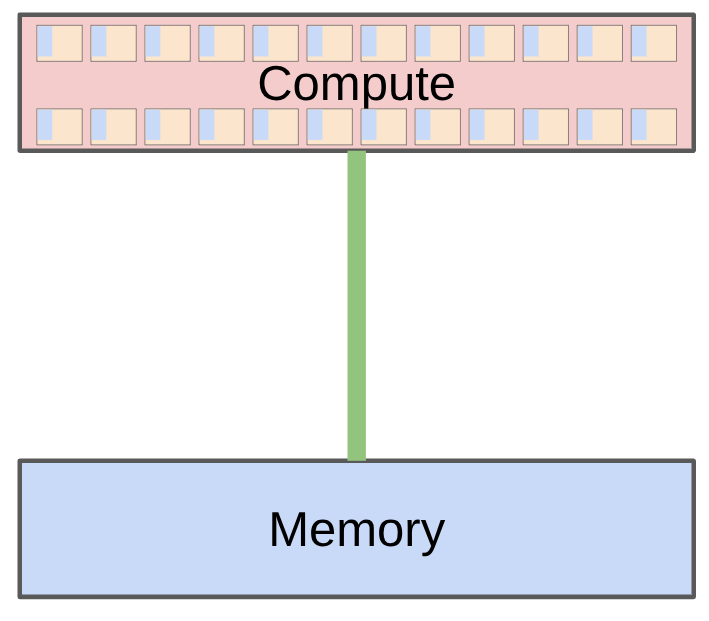

**记录步骤 246 · arithmetic_intensity · L430**

```python
text("How to compute a thing:")
```

How to compute a thing:

**记录步骤 247 · arithmetic_intensity · L431**

```python
text("1. Send inputs from memory to accelerator")
```

1. Send inputs from memory to accelerator

**记录步骤 248 · arithmetic_intensity · L432**

```python
text("2. Perform computation")
```

2. Perform computation

**记录步骤 249 · arithmetic_intensity · L433**

```python
text("3. Send outputs from accelerator to memory")
```

3. Send outputs from accelerator to memory

**记录步骤 250 · arithmetic_intensity · L435**

```python
text("How long does this take?")
```

How long does this take?

**记录步骤 251 · arithmetic_intensity · L437**

```python
text("Depends on two things:")
```

Depends on two things:

**记录步骤 252 · arithmetic_intensity · L438**

```python
text("1. Accelerator speed (FLOP/s)")
```

1. Accelerator speed (FLOP/s)

**记录步骤 253 · arithmetic_intensity · L439**

```python
text("1. Memory bandwidth (bytes/s)")
```

1. Memory bandwidth (bytes/s)

**记录步骤 254 · arithmetic_intensity · L440**

```python
assert h100_flop_per_sec == 1979e12 / 2  # Half without sparsity
```

**记录步骤 255 · arithmetic_intensity · L441**

```python
assert h100_bytes_per_sec == 3.35e12
```

**记录步骤 256 · arithmetic_intensity · L443**

```python
arithmetic_intensity_relu()
```

**记录步骤 257 · arithmetic_intensity_relu · L453**

```python
def arithmetic_intensity_relu():
```

**记录步骤 258 · arithmetic_intensity_relu · L454**

```python
n = 1024 * 1024
```

**记录步骤 259 · arithmetic_intensity_relu · L455**

```python
x = torch.ones(n, dtype=torch.bfloat16, device=cuda_if_available())
```

**记录步骤 260 · arithmetic_intensity_relu · L456**

```python
y = torch.relu(x)
```

**记录步骤 261 · arithmetic_intensity_relu · L458**

```python
bytes = (2 * n) + (2 * n)  # Read x, write y (bf16 is 2 bytes/float)
```

**记录步骤 262 · arithmetic_intensity_relu · L459**

```python
flops = n  # n comparisons
```

**记录步骤 263 · arithmetic_intensity_relu · L461**

```python
communication_time = bytes / h100_bytes_per_sec  # @inspect communication_time
```

原课堂变量快照：
```json
{
  "communication_time": {
    "type": "float",
    "contents": 1.2520310447761193e-06,
    "dtype": null,
    "shape": null
  }
}
```

**记录步骤 264 · arithmetic_intensity_relu · L462**

```python
computation_time = flops / h100_flop_per_sec  # @inspect computation_time
```

原课堂变量快照：
```json
{
  "computation_time": {
    "type": "float",
    "contents": 1.0597028802425467e-09,
    "dtype": null,
    "shape": null
  }
}
```

**记录步骤 265 · arithmetic_intensity_relu · L464**

```python
text("Assume we can overlap communication and computation perfectly.")
```

Assume we can overlap communication and computation perfectly.

**记录步骤 266 · arithmetic_intensity_relu · L465**

```python
total_time = max(communication_time, computation_time)  # @inspect total_time
```

原课堂变量快照：
```json
{
  "total_time": {
    "type": "float",
    "contents": 1.2520310447761193e-06,
    "dtype": null,
    "shape": null
  }
}
```

**记录步骤 267 · arithmetic_intensity_relu · L467**

```python
text("What is the bottleneck?")
```

What is the bottleneck?

**记录步骤 268 · arithmetic_intensity_relu · L468**

```python
text("- Memory-bound: communication time > computation time")
```

- Memory-bound: communication time > computation time

**记录步骤 269 · arithmetic_intensity_relu · L469**

```python
text("- Compute-bound: computation time > communication time")
```

- Compute-bound: computation time > communication time

**记录步骤 270 · arithmetic_intensity_relu · L471**

```python
text("In this case, ReLU is memory-bound.")
```

In this case, ReLU is memory-bound.

**记录步骤 271 · arithmetic_intensity_relu · L473**

```python
text("Alternative way to see this:")
```

Alternative way to see this:

**记录步骤 272 · arithmetic_intensity_relu · L474**

```python
text("Accelerator intensity: how much work can the accelerator do per byte transferred?")
```

Accelerator intensity: how much work can the accelerator do per byte transferred?

**记录步骤 273 · arithmetic_intensity_relu · L475**

```python
h100_accelerator_intensity = h100_flop_per_sec / h100_bytes_per_sec  # @inspect h100_accelerator_intensity
```

原课堂变量快照：
```json
{
  "h100_accelerator_intensity": {
    "type": "float",
    "contents": 295.3731343283582,
    "dtype": null,
    "shape": null
  }
}
```

**记录步骤 274 · arithmetic_intensity_relu · L477**

```python
text("Arithmetic intensity: how much actual work per byte for this workload?")
```

Arithmetic intensity: how much actual work per byte for this workload?

**记录步骤 275 · arithmetic_intensity_relu · L478**

```python
arithmetic_intensity = flops / bytes  # ~1/2 @inspect arithmetic_intensity
```

原课堂变量快照：
```json
{
  "arithmetic_intensity": {
    "type": "float",
    "contents": 0.25,
    "dtype": null,
    "shape": null
  }
}
```

**记录步骤 276 · arithmetic_intensity_relu · L480**

```python
text("What is the bottleneck")
```

What is the bottleneck

**记录步骤 277 · arithmetic_intensity_relu · L481**

```python
text("- Memory-bound: arithmetic intensity < accelerator intensity")
```

- Memory-bound: arithmetic intensity < accelerator intensity

**记录步骤 278 · arithmetic_intensity_relu · L482**

```python
text("- Compute-bound: arithmetic intensity > accelerator intensity")
```

- Compute-bound: arithmetic intensity > accelerator intensity

**记录步骤 279 · arithmetic_intensity_relu · L484**

```python
assert arithmetic_intensity < h100_accelerator_intensity
```

**记录步骤 280 · arithmetic_intensity_relu · L486**

```python
text("In general, we'll find ourselves memory bound, so higher arithmetic intensity is good!")
```

In general, we'll find ourselves memory bound, so higher arithmetic intensity is good!

**记录步骤 281 · arithmetic_intensity · L443**

```python
arithmetic_intensity_relu()
```

**记录步骤 282 · arithmetic_intensity · L444**

```python
arithmetic_intensity_gelu()
```

**记录步骤 283 · arithmetic_intensity_gelu · L489**

```python
def arithmetic_intensity_gelu():
```

**记录步骤 284 · arithmetic_intensity_gelu · L490**

```python
n = 1024
```

**记录步骤 285 · arithmetic_intensity_gelu · L491**

```python
x = torch.ones(n, dtype=torch.bfloat16, device=cuda_if_available())
```

**记录步骤 286 · arithmetic_intensity_gelu · L492**

```python
y = F.gelu(x)  # GELU(x) = 0.5 x (1 + tanh(sqrt(2/pi) (x + 0.044715 x^3)))
```

**记录步骤 287 · arithmetic_intensity_gelu · L494**

```python
bytes = (2 * n) + (2 * n)  # Read x, write y (bf16 is 2 bytes/float)
```

**记录步骤 288 · arithmetic_intensity_gelu · L495**

```python
flops = 20 * n  # tanh can approximated in various ways (e.g., polynomial)
```

**记录步骤 289 · arithmetic_intensity_gelu · L497**

```python
arithmetic_intensity = flops / bytes  # @inspect arithmetic_intensity
```

原课堂变量快照：
```json
{
  "arithmetic_intensity": {
    "type": "float",
    "contents": 5.0,
    "dtype": null,
    "shape": null
  }
}
```

**记录步骤 290 · arithmetic_intensity_gelu · L499**

```python
h100_accelerator_intensity = h100_flop_per_sec / h100_bytes_per_sec  # @inspect h100_accelerator_intensity
```

原课堂变量快照：
```json
{
  "h100_accelerator_intensity": {
    "type": "float",
    "contents": 295.3731343283582,
    "dtype": null,
    "shape": null
  }
}
```

**记录步骤 291 · arithmetic_intensity_gelu · L500**

```python
assert arithmetic_intensity < h100_accelerator_intensity
```

**记录步骤 292 · arithmetic_intensity_gelu · L502**

```python
text("Note that GeLU does more work than ReLU per byte moved, so it has higher arithmetic intensity.")
```

Note that GeLU does more work than ReLU per byte moved, so it has higher arithmetic intensity.

**记录步骤 293 · arithmetic_intensity_gelu · L503**

```python
text("But still memory-bound!")
```

But still memory-bound!

**记录步骤 294 · arithmetic_intensity_gelu · L504**

```python
text("In other words, ReLU is not faster than GeLU (when doing things in an isolated way).")
```

In other words, ReLU is not faster than GeLU (when doing things in an isolated way).

**记录步骤 295 · arithmetic_intensity · L444**

```python
arithmetic_intensity_gelu()
```

**记录步骤 296 · arithmetic_intensity · L445**

```python
arithmetic_intensity_dot_product()
```

**记录步骤 297 · arithmetic_intensity_dot_product · L507**

```python
def arithmetic_intensity_dot_product():
```

**记录步骤 298 · arithmetic_intensity_dot_product · L508**

```python
n = 1024
```

**记录步骤 299 · arithmetic_intensity_dot_product · L509**

```python
x = torch.ones(n, dtype=torch.bfloat16, device=cuda_if_available())
```

**记录步骤 300 · arithmetic_intensity_dot_product · L510**

```python
w = torch.ones(n, dtype=torch.bfloat16, device=cuda_if_available())
```

**记录步骤 301 · arithmetic_intensity_dot_product · L511**

```python
y = x @ w
```

**记录步骤 302 · arithmetic_intensity_dot_product · L513**

```python
bytes = (2 * n) + (2 * n) + 2  # Read x, read w, write y
```

**记录步骤 303 · arithmetic_intensity_dot_product · L514**

```python
flops = 2 * n - 1  # n multiplications, n-1 additions
```

**记录步骤 304 · arithmetic_intensity_dot_product · L516**

```python
arithmetic_intensity = flops / bytes  # ~1/2 @inspect arithmetic_intensity
```

原课堂变量快照：
```json
{
  "arithmetic_intensity": {
    "type": "float",
    "contents": 0.4995119570522206,
    "dtype": null,
    "shape": null
  }
}
```

**记录步骤 305 · arithmetic_intensity_dot_product · L518**

```python
h100_accelerator_intensity = h100_flop_per_sec / h100_bytes_per_sec  # @inspect h100_accelerator_intensity
```

原课堂变量快照：
```json
{
  "h100_accelerator_intensity": {
    "type": "float",
    "contents": 295.3731343283582,
    "dtype": null,
    "shape": null
  }
}
```

**记录步骤 306 · arithmetic_intensity_dot_product · L519**

```python
assert arithmetic_intensity < h100_accelerator_intensity
```

**记录步骤 307 · arithmetic_intensity_dot_product · L520**

```python
text("Memory-bound!")
```

Memory-bound!

**记录步骤 308 · arithmetic_intensity · L445**

```python
arithmetic_intensity_dot_product()
```

**记录步骤 309 · arithmetic_intensity · L446**

```python
arithmetic_intensity_matrix_vector_product()
```

**记录步骤 310 · arithmetic_intensity_matrix_vector_product · L523**

```python
def arithmetic_intensity_matrix_vector_product():
```

**记录步骤 311 · arithmetic_intensity_matrix_vector_product · L524**

```python
n = 1024
```

**记录步骤 312 · arithmetic_intensity_matrix_vector_product · L525**

```python
x = torch.ones(n, dtype=torch.bfloat16, device=cuda_if_available())
```

**记录步骤 313 · arithmetic_intensity_matrix_vector_product · L526**

```python
w = torch.ones(n, n, dtype=torch.bfloat16, device=cuda_if_available())
```

**记录步骤 314 · arithmetic_intensity_matrix_vector_product · L527**

```python
y = x @ w
```

**记录步骤 315 · arithmetic_intensity_matrix_vector_product · L529**

```python
bytes = (2 * n) + (2 * n * n) + (2 * n)  # Read x, read w, write y
```

**记录步骤 316 · arithmetic_intensity_matrix_vector_product · L530**

```python
flops = n * (2 * n - 1)  # n dot-products
```

**记录步骤 317 · arithmetic_intensity_matrix_vector_product · L532**

```python
arithmetic_intensity = flops / bytes  # ~1 @inspect arithmetic_intensity
```

原课堂变量快照：
```json
{
  "arithmetic_intensity": {
    "type": "float",
    "contents": 0.9975633528265108,
    "dtype": null,
    "shape": null
  }
}
```

**记录步骤 318 · arithmetic_intensity_matrix_vector_product · L534**

```python
h100_accelerator_intensity = h100_flop_per_sec / h100_bytes_per_sec  # @inspect h100_accelerator_intensity
```

原课堂变量快照：
```json
{
  "h100_accelerator_intensity": {
    "type": "float",
    "contents": 295.3731343283582,
    "dtype": null,
    "shape": null
  }
}
```

**记录步骤 319 · arithmetic_intensity_matrix_vector_product · L535**

```python
assert arithmetic_intensity < h100_accelerator_intensity
```

**记录步骤 320 · arithmetic_intensity_matrix_vector_product · L536**

```python
text("Memory-bound!")
```

Memory-bound!

**记录步骤 321 · arithmetic_intensity · L446**

```python
arithmetic_intensity_matrix_vector_product()
```

**记录步骤 322 · arithmetic_intensity · L447**

```python
arithmetic_intensity_matmul()
```

**记录步骤 323 · arithmetic_intensity_matmul · L538**

```python
def arithmetic_intensity_matmul():
```

**记录步骤 324 · arithmetic_intensity_matmul · L539**

```python
n = 1024
```

**记录步骤 325 · arithmetic_intensity_matmul · L540**

```python
x = torch.ones(n, n, dtype=torch.bfloat16, device=cuda_if_available())
```

**记录步骤 326 · arithmetic_intensity_matmul · L541**

```python
w = torch.ones(n, n, dtype=torch.bfloat16, device=cuda_if_available())
```

**记录步骤 327 · arithmetic_intensity_matmul · L542**

```python
y = x @ w
```

**记录步骤 328 · arithmetic_intensity_matmul · L544**

```python
bytes = (2 * n * n) + (2 * n * n) + (2 * n * n)  # Read x, read w, write y
```

**记录步骤 329 · arithmetic_intensity_matmul · L545**

```python
flops = n * n * (2 * n - 1)  # n^2 dot products
```

**记录步骤 330 · arithmetic_intensity_matmul · L547**

```python
arithmetic_intensity = flops / bytes  # ~n/3 @inspect arithmetic_intensity
```

原课堂变量快照：
```json
{
  "arithmetic_intensity": {
    "type": "float",
    "contents": 341.1666666666667,
    "dtype": null,
    "shape": null
  }
}
```

**记录步骤 331 · arithmetic_intensity_matmul · L549**

```python
h100_accelerator_intensity = h100_flop_per_sec / h100_bytes_per_sec  # @inspect h100_accelerator_intensity
```

原课堂变量快照：
```json
{
  "h100_accelerator_intensity": {
    "type": "float",
    "contents": 295.3731343283582,
    "dtype": null,
    "shape": null
  }
}
```

**记录步骤 332 · arithmetic_intensity_matmul · L550**

```python
assert arithmetic_intensity > h100_accelerator_intensity
```

**记录步骤 333 · arithmetic_intensity_matmul · L551**

```python
text("Finally, compute-bound!")
```

Finally, compute-bound!

**记录步骤 334 · arithmetic_intensity_matmul · L553**

```python
text("As long as we have large matrices, we're compute-bound (saturating the accelerator).")
```

As long as we have large matrices, we're compute-bound (saturating the accelerator).

**记录步骤 335 · arithmetic_intensity_matmul · L554**

```python
text("Training Transformers involves big matrix multiplications")
```

Training Transformers involves big matrix multiplications

**记录步骤 336 · arithmetic_intensity_matmul · L555**

```python
text("Matrix-vector product is what happens during inference, which is why inference is memory-bound.")
```

Matrix-vector product is what happens during inference, which is why inference is memory-bound.

**记录步骤 337 · arithmetic_intensity_matmul · L557**

```python
text("Note: arithmetic/accelerator intensity depends on the precision (bf16 versus fp32)")
```

Note: arithmetic/accelerator intensity depends on the precision (bf16 versus fp32)

**记录步骤 338 · arithmetic_intensity · L447**

```python
arithmetic_intensity_matmul()
```

**记录步骤 339 · arithmetic_intensity · L450**

```python
roofline_plots()
```

**记录步骤 340 · roofline_plots · L560**

```python
def roofline_plots():
```

**记录步骤 341 · roofline_plots · L561**

```python
text("We can visualize the relationship between arithmetic intensity and performance using roofline plots.")
```

We can visualize the relationship between arithmetic intensity and performance using roofline plots.

**记录步骤 342 · roofline_plots · L562**

```python
image("https://jax-ml.github.io/scaling-book/assets/img/roofline-improved-1400.webp", width=600)
```

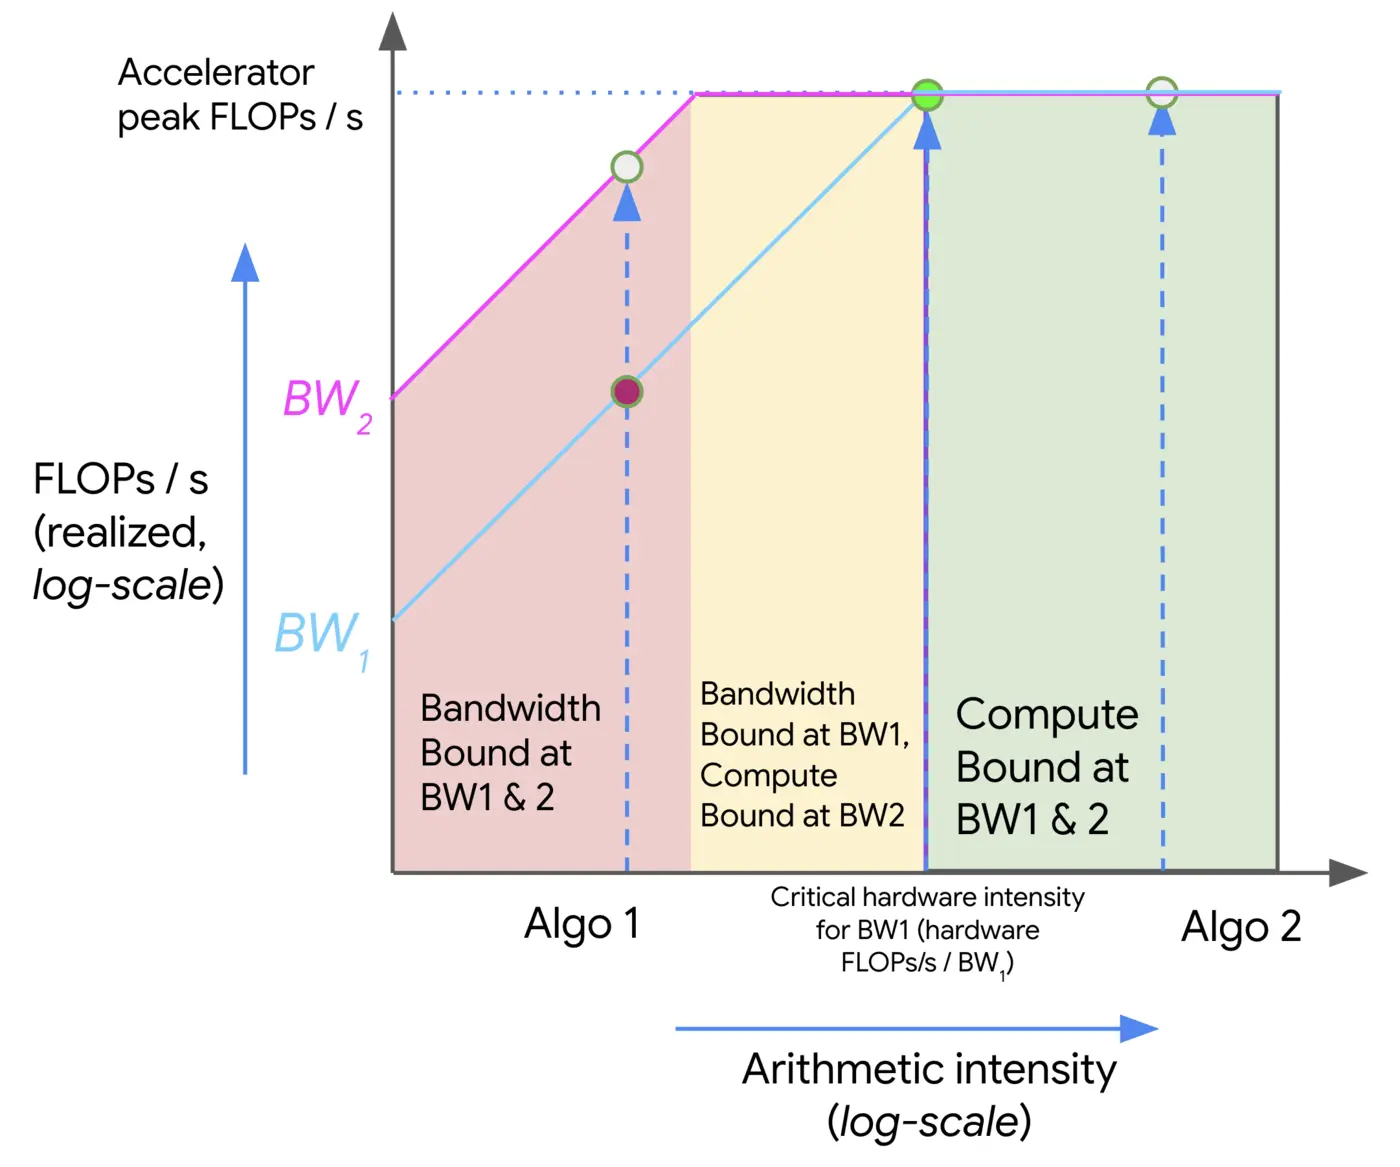

**记录步骤 343 · roofline_plots · L563**

```python
text("- Each slice on the x-axis is a particular computation (with some arithmetic intensity)")
```

- Each slice on the x-axis is a particular computation (with some arithmetic intensity)

**记录步骤 344 · roofline_plots · L564**

```python
text("- Each piecewise linear function corresponds to a particular hardware")
```

- Each piecewise linear function corresponds to a particular hardware

**记录步骤 345 · roofline_plots · L565**

```python
text("- Kink is the accelerator intensity (transition from memory-bound to compute-bound)")
```

- Kink is the accelerator intensity (transition from memory-bound to compute-bound)

**记录步骤 346 · roofline_plots · L567**

```python
link("https://jax-ml.github.io/scaling-book/roofline/")
```

[[https://jax-ml.github.io/scaling-book/roofline/]](https://jax-ml.github.io/scaling-book/roofline/)

**记录步骤 347 · arithmetic_intensity · L450**

```python
roofline_plots()
```

## main

**记录步骤 348 · main · L49**

```python
arithmetic_intensity()
```

**记录步骤 349 · main · L52**

```python
deep_linear_network()
```

## deep_linear_network

**记录步骤 350 · deep_linear_network · L570**

```python
def deep_linear_network():
```

**记录步骤 351 · deep_linear_network · L571**

```python
image("images/deep-network.png", width=700)
```

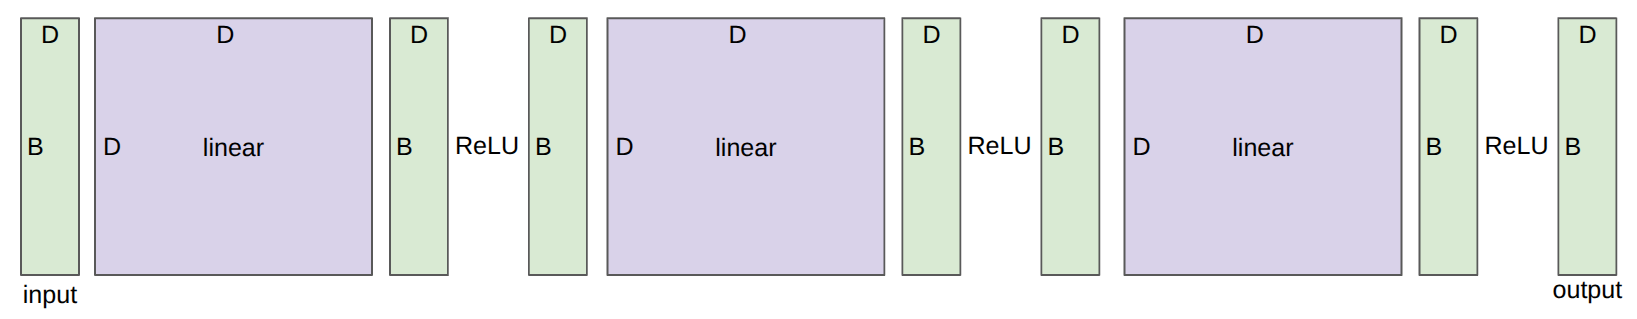

**记录步骤 352 · deep_linear_network · L572**

```python
text("Consider a deep network with L layers and D-dimensional inputs, activations, and outputs.")
```

Consider a deep network with L layers and D-dimensional inputs, activations, and outputs.

**记录步骤 353 · deep_linear_network · L575**

```python
D = 8  # Dimensionality of input, activations, and output
```

**记录步骤 354 · deep_linear_network · L576**

```python
L = 3  # Number of layers
```

**记录步骤 355 · deep_linear_network · L577**

```python
model = DeepNetwork(dim=D, num_layers=L).to(cuda_if_available())
```

**记录步骤 356 · __init__ · L602**

```python
def __init__(self, dim: int, num_layers: int):
```

**记录步骤 357 · __init__ · L603**

```python
super().__init__()
```

**记录步骤 358 · __init__ · L604**

```python
self.layers = nn.ModuleList([Block(dim) for i in range(num_layers)])
```

**记录步骤 359 · __init__ · L590**

```python
def __init__(self, dim: int):
```

**记录步骤 360 · __init__ · L591**

```python
super().__init__()
```

**记录步骤 361 · __init__ · L592**

```python
self.weight = nn.Parameter(torch.randn(dim, dim) / np.sqrt(dim))
```

**记录步骤 362 · __init__ · L590**

```python
def __init__(self, dim: int):
```

**记录步骤 363 · __init__ · L591**

```python
super().__init__()
```

**记录步骤 364 · __init__ · L592**

```python
self.weight = nn.Parameter(torch.randn(dim, dim) / np.sqrt(dim))
```

**记录步骤 365 · __init__ · L590**

```python
def __init__(self, dim: int):
```

**记录步骤 366 · __init__ · L591**

```python
super().__init__()
```

**记录步骤 367 · __init__ · L592**

```python
self.weight = nn.Parameter(torch.randn(dim, dim) / np.sqrt(dim))
```

**记录步骤 368 · __init__ · L604**

```python
self.layers = nn.ModuleList([Block(dim) for i in range(num_layers)])
```

**记录步骤 369 · deep_linear_network · L577**

```python
model = DeepNetwork(dim=D, num_layers=L).to(cuda_if_available())
```

**记录步骤 370 · deep_linear_network · L579**

```python
num_parameters = get_num_parameters(model)  # @inspect num_parameters @stepover
```

原课堂变量快照：
```json
{
  "num_parameters": {
    "type": "int",
    "contents": 192,
    "dtype": null,
    "shape": null
  }
}
```

**记录步骤 371 · deep_linear_network · L580**

```python
assert num_parameters == (D * D) * L
```

**记录步骤 372 · deep_linear_network · L583**

```python
B = 4  # Batch size
```

**记录步骤 373 · deep_linear_network · L584**

```python
x = torch.randn(B, D, device=cuda_if_available())  # @inspect x
```

原课堂变量快照：
```json
{
  "x": {
    "type": "torch.Tensor",
    "contents": [
      [
        0.1801944524049759,
        -0.6072437763214111,
        0.9107983708381653,
        -0.47816023230552673,
        0.52882981300354,
        -0.10392139852046967,
        -0.08317895233631134,
        -1.584515929222107
      ],
      [
        -1.1273322105407715,
        -0.16201148927211761,
        -0.3402184545993805,
        -0.2841821610927582,
        -0.40223315358161926,
        -1.3593215942382812,
        -0.9313412308692932,
        1.4359203577041626
      ],
      [
        -2.020500659942627,
        -0.014517650008201599,
        -0.16039998829364777,
        -0.8584300875663757,
        0.6975440382957458,
        -2.7609059810638428,
        0.5555264353752136,
        0.09382456541061401
      ],
      [
        0.9989727735519409,
        0.9613957405090332,
        2.015348196029663,
        1.1551806926727295,
        -2.075718879699707,
        -1.658756971359253,
        -1.047814130783081,
        0.4651208221912384
      ]
    ],
    "dtype": "torch.float32",
    "shape": [
      4,
      8
    ]
  }
}
```

**记录步骤 374 · deep_linear_network · L585**

```python
y = model(x)  # @inspect y
```

**记录步骤 375 · forward · L606**

```python
def forward(self, x: torch.Tensor) -> torch.Tensor:
```

**记录步骤 376 · forward · L608**

```python
for layer in self.layers:
```

**记录步骤 377 · forward · L609**

```python
x = layer(x)  # @stepover
```

**记录步骤 378 · forward · L608**

```python
for layer in self.layers:
```

**记录步骤 379 · forward · L609**

```python
x = layer(x)  # @stepover
```

**记录步骤 380 · forward · L594**

```python
def forward(self, x: torch.Tensor) -> torch.Tensor:
```

**记录步骤 381 · forward · L595**

```python
x = x @ self.weight  # Linear
```

**记录步骤 382 · forward · L596**

```python
x = F.relu(x)        # Activation
```

**记录步骤 383 · forward · L597**

```python
return x
```

**记录步骤 384 · forward · L609**

```python
x = layer(x)  # @stepover
```

**记录步骤 385 · forward · L608**

```python
for layer in self.layers:
```

**记录步骤 386 · forward · L609**

```python
x = layer(x)  # @stepover
```

**记录步骤 387 · forward · L608**

```python
for layer in self.layers:
```

**记录步骤 388 · forward · L610**

```python
return x
```

**记录步骤 389 · deep_linear_network · L585**

```python
y = model(x)  # @inspect y
```

原课堂变量快照：
```json
{
  "y": {
    "type": "torch.Tensor",
    "contents": [
      [
        0.05365755036473274,
        0.24389001727104187,
        0.1550859957933426,
        0.1316402703523636,
        0.17956000566482544,
        0.0,
        0.0,
        0.012788483873009682
      ],
      [
        0.04939380660653114,
        0.0,
        0.0,
        0.19272518157958984,
        0.0,
        0.0,
        0.0,
        0.14427495002746582
      ],
      [
        0.10415778309106827,
        0.1818353682756424,
        0.0,
        0.2447396218776703,
        0.0,
        0.0,
        0.0,
        0.1545974612236023
      ],
      [
        0.0,
        0.3823801875114441,
        0.3604673743247986,
        0.10922253131866455,
        0.14880059659481049,
        0.0,
        0.0,
        0.0
      ]
    ],
    "dtype": "torch.float32",
    "shape": [
      4,
      8
    ]
  }
}
```

## main

**记录步骤 390 · main · L52**

```python
deep_linear_network()
```

**记录步骤 391 · main · L53**

```python
gradients_basics()
```

## gradients_basics

**记录步骤 392 · gradients_basics · L350**

```python
def gradients_basics():
```

**记录步骤 393 · gradients_basics · L351**

```python
text("So far, we've constructed tensors (which correspond to either parameters or data) and passed them through operations (forward).")
```

So far, we've constructed tensors (which correspond to either parameters or data) and passed them through operations (forward).

**记录步骤 394 · gradients_basics · L352**

```python
text("Now, we're going to compute the gradient (backward).")
```

Now, we're going to compute the gradient (backward).

**记录步骤 395 · gradients_basics · L354**

```python
text("As a simple example, let's consider the simple linear model:")
```

As a simple example, let's consider the simple linear model:

**记录步骤 396 · gradients_basics · L355**

```python
text("y = 0.5 (x * w - 5)^2")
```

y = 0.5 (x * w - 5)^2

**记录步骤 397 · gradients_basics · L357**

```python
text("Forward pass: compute loss")
```

Forward pass: compute loss

**记录步骤 398 · gradients_basics · L358**

```python
x = torch.tensor([1., 2, 3])
```

**记录步骤 399 · gradients_basics · L359**

```python
w = torch.tensor([1., 1, 1], requires_grad=True)  # Want gradient
```

**记录步骤 400 · gradients_basics · L360**

```python
pred_y = x @ w
```

**记录步骤 401 · gradients_basics · L361**

```python
loss = 0.5 * (pred_y - 5).pow(2)
```

**记录步骤 402 · gradients_basics · L363**

```python
text("Backward pass: compute gradients")
```

Backward pass: compute gradients

**记录步骤 403 · gradients_basics · L364**

```python
loss.backward()
```

**记录步骤 404 · gradients_basics · L365**

```python
assert loss.grad is None
```

**记录步骤 405 · gradients_basics · L366**

```python
assert pred_y.grad is None
```

**记录步骤 406 · gradients_basics · L367**

```python
assert x.grad is None
```

**记录步骤 407 · gradients_basics · L368**

```python
assert torch.equal(w.grad, torch.tensor([1, 2, 3]))  # @inspect w.grad
```

原课堂变量快照：
```json
{
  "w.grad": {
    "type": "torch.Tensor",
    "contents": [
      1.0,
      2.0,
      3.0
    ],
    "dtype": "torch.float32",
    "shape": [
      3
    ]
  }
}
```

## main

**记录步骤 408 · main · L53**

```python
gradients_basics()
```

**记录步骤 409 · main · L54**

```python
gradients_flops()
```

## gradients_flops

**记录步骤 410 · gradients_flops · L371**

```python
def gradients_flops():
```

**记录步骤 411 · gradients_flops · L372**

```python
text("Let us count the FLOPs for computing gradients.")
```

Let us count the FLOPs for computing gradients.

**记录步骤 412 · gradients_flops · L374**

```python
image("images/deep-network.png", width=700)
```

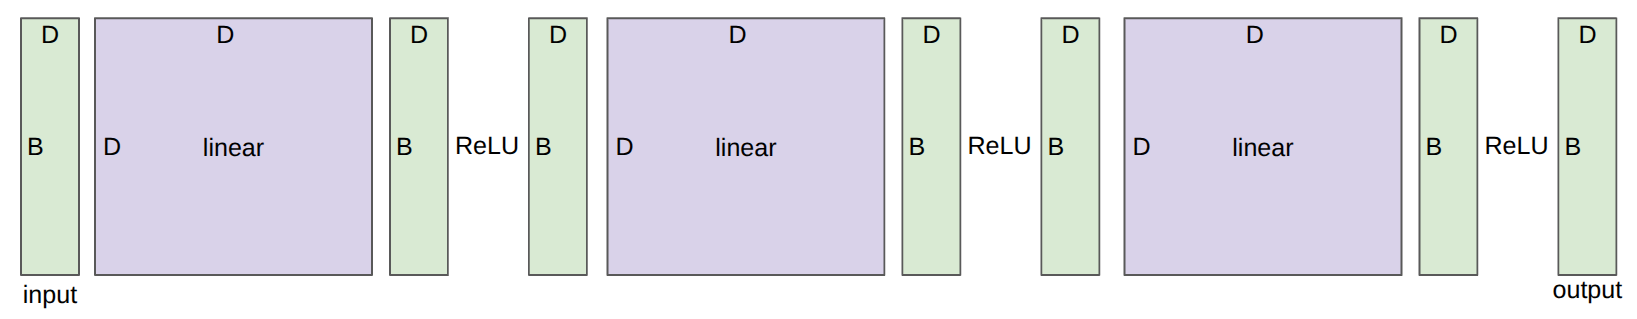

**记录步骤 413 · gradients_flops · L376**

```python
B = 1024  # Number of points
```

**记录步骤 414 · gradients_flops · L377**

```python
D = 256   # Dimension
```

**记录步骤 415 · gradients_flops · L379**

```python
text("Define a simplified model (2-layer linear network):")
```

Define a simplified model (2-layer linear network):

**记录步骤 416 · gradients_flops · L380**

```python
x = torch.ones(B, D, device=cuda_if_available())
```

**记录步骤 417 · gradients_flops · L381**

```python
w1 = torch.randn(D, D, device=cuda_if_available(), requires_grad=True)
```

**记录步骤 418 · gradients_flops · L382**

```python
w2 = torch.randn(D, D, device=cuda_if_available(), requires_grad=True)
```

**记录步骤 419 · gradients_flops · L385**

```python
h1 = einsum(x, w1, "batch in, in out -> batch out")  # x @ w1
```

**记录步骤 420 · gradients_flops · L386**

```python
h2 = einsum(h1, w2, "batch in, in out -> batch out")  # h1 @ w2
```

**记录步骤 421 · gradients_flops · L387**

```python
loss = (h2.mean() - 0)**2  # Regress everything to 0 (arbitrary)
```

**记录步骤 422 · gradients_flops · L390**

```python
h1.retain_grad()  # For debugging
```

**记录步骤 423 · gradients_flops · L391**

```python
h2.retain_grad()  # For debugging
```

**记录步骤 424 · gradients_flops · L392**

```python
loss.backward()
```

**记录步骤 425 · gradients_flops · L394**

```python
text("## Zoom in on one layer")
```

## Zoom in on one layer

**记录步骤 426 · gradients_flops · L395**

```python
text("Let's focus on the second layer h1 --w2--> h2.")
```

Let's focus on the second layer h1 --w2--> h2.

**记录步骤 427 · gradients_flops · L397**

```python
text("**Forward pass**: Recall the number of forward FLOPs (bf16): ")
```

**Forward pass**: Recall the number of forward FLOPs (bf16): 

**记录步骤 428 · gradients_flops · L398**

```python
num_forward_flops = 2 * B * D * D   # @inspect num_forward_flops
```

原课堂变量快照：
```json
{
  "num_forward_flops": {
    "type": "int",
    "contents": 134217728,
    "dtype": null,
    "shape": null
  }
}
```

**记录步骤 429 · gradients_flops · L400**

```python
text("**Backward pass**: How many FLOPs is running the backward pass?")
```

**Backward pass**: How many FLOPs is running the backward pass?

**记录步骤 430 · gradients_flops · L402**

```python
text("We need to compute:")
```

We need to compute:

**记录步骤 431 · gradients_flops · L403**

```python
text("- h1.grad = d loss / d h1")
```

- h1.grad = d loss / d h1

**记录步骤 432 · gradients_flops · L404**

```python
text("- w2.grad = d loss / d w2")
```

- w2.grad = d loss / d w2

**记录步骤 433 · gradients_flops · L406**

```python
h1_grad = einsum(h2.grad, w2, "batch out, in out -> batch in")
```

**记录步骤 434 · gradients_flops · L407**

```python
assert torch.allclose(h1.grad, h1_grad)
```

**记录步骤 435 · gradients_flops · L409**

```python
w2_grad = einsum(h2.grad, h1, "batch out, batch in -> in out")
```

**记录步骤 436 · gradients_flops · L410**

```python
assert torch.allclose(w2.grad, w2_grad)
```

**记录步骤 437 · gradients_flops · L412**

```python
num_backward_flops = (2 * B * D * D) + (2 * B * D * D)  # @inspect num_backward_flops
```

原课堂变量快照：
```json
{
  "num_backward_flops": {
    "type": "int",
    "contents": 268435456,
    "dtype": null,
    "shape": null
  }
}
```

**记录步骤 438 · gradients_flops · L414**

```python
text("Note that the backward pass is 2x more expensive than the forward pass.")
```

Note that the backward pass is 2x more expensive than the forward pass.

**记录步骤 439 · gradients_flops · L416**

```python
text("## Consider all layers")
```

## Consider all layers

**记录步骤 440 · gradients_flops · L417**

```python
text("This was just for w2, need to apply it to all parameters in the network.")
```

This was just for w2, need to apply it to all parameters in the network.

**记录步骤 441 · gradients_flops · L419**

```python
text("Putting it togther:")
```

Putting it togther:

**记录步骤 442 · gradients_flops · L420**

```python
text("- Forward pass: 2 (# data points) (# parameters) FLOPs")
```

- Forward pass: 2 (# data points) (# parameters) FLOPs

**记录步骤 443 · gradients_flops · L421**

```python
text("- Backward pass: 4 (# data points) (# parameters) FLOPs")
```

- Backward pass: 4 (# data points) (# parameters) FLOPs

**记录步骤 444 · gradients_flops · L422**

```python
text("- Total: 6 (# data points) (# parameters) FLOPs")
```

- Total: 6 (# data points) (# parameters) FLOPs

**记录步骤 445 · gradients_flops · L424**

```python
text("This is for multilayer perceptrons (MLPs)")
```

This is for multilayer perceptrons (MLPs)

**记录步骤 446 · gradients_flops · L425**

```python
text("...but it turns out to be a good approximation for Transformers for short context lengths as well.")
```

...but it turns out to be a good approximation for Transformers for short context lengths as well.

## main

**记录步骤 447 · main · L54**

```python
gradients_flops()
```

**记录步骤 448 · main · L55**

```python
optimizer()
```

## optimizer

**记录步骤 449 · optimizer · L613**

```python
def optimizer():
```

**记录步骤 450 · optimizer · L614**

```python
text("Recall our deep network.")
```

Recall our deep network.

**记录步骤 451 · optimizer · L615**

```python
B = 2  # Batch size
```

**记录步骤 452 · optimizer · L616**

```python
D = 4  # Dimensionality of input, activations, and output
```

**记录步骤 453 · optimizer · L617**

```python
L = 3  # Number of layers
```

**记录步骤 454 · optimizer · L618**

```python
model = DeepNetwork(dim=D, num_layers=L).to(cuda_if_available())  # @stepover
```

**记录步骤 455 · optimizer · L620**

```python
text("Let's define the AdaGrad optimizer")
```

Let's define the AdaGrad optimizer

**记录步骤 456 · optimizer · L621**

```python
text("- momentum = SGD + exponential averaging of grad")
```

- momentum = SGD + exponential averaging of grad

**记录步骤 457 · optimizer · L622**

```python
text("- AdaGrad = SGD + averaging by grad^2")
```

- AdaGrad = SGD + averaging by grad^2

**记录步骤 458 · optimizer · L623**

```python
text("- RMSProp = AdaGrad + exponentially averaging of grad^2")
```

- RMSProp = AdaGrad + exponentially averaging of grad^2

**记录步骤 459 · optimizer · L624**

```python
text("- Adam = RMSProp + momentum")
```

- Adam = RMSProp + momentum

**记录步骤 460 · optimizer · L626**

```python
text("AdaGrad "), link(adagrad_2011)
```

AdaGrad 

[[Duchi+ 2011]](https://www.jmlr.org/papers/volume12/duchi11a/duchi11a.pdf)

**记录步骤 461 · optimizer · L627**

```python
optimizer = AdaGrad(model.parameters(), lr=0.01)  # @stepover
```

**记录步骤 462 · optimizer · L628**

```python
state = model.state_dict()  # @inspect state
```

原课堂变量快照：
```json
{
  "state": {
    "type": "collections.OrderedDict",
    "contents": {
      "layers.0.weight": {
        "type": "torch.Tensor",
        "contents": [
          [
            0.08194047212600708,
            0.10775608569383621,
            0.7011701464653015,
            0.22478367388248444
          ],
          [
            0.3266134262084961,
            1.0194047689437866,
            0.4465654790401459,
            -0.39747822284698486
          ],
          [
            0.1295507550239563,
            0.1396379917860031,
            -0.4521281123161316,
            -0.5650829672813416
          ],
          [
            -0.212665393948555,
            -1.0388363599777222,
            0.6058981418609619,
            -0.03931014612317085
          ]
        ],
        "dtype": "torch.float32",
        "shape": [
          4,
          4
        ]
      },
      "layers.1.weight": {
        "type": "torch.Tensor",
        "contents": [
          [
            0.006210218649357557,
            -0.5304369330406189,
            -0.8498334884643555,
            -0.20047669112682343
          ],
          [
            -0.3833449184894562,
            1.2034804821014404,
            -0.25192707777023315,
            -0.8855014443397522
          ],
          [
            0.44087687134742737,
            0.30339327454566956,
            0.747622013092041,
            -0.44493669271469116
          ],
          [
            0.04413896054029465,
            0.4640462100505829,
            0.07946481555700302,
            0.2364865243434906
          ]
        ],
        "dtype": "torch.float32",
        "shape": [
          4,
          4
        ]
      },
      "layers.2.weight": {
        "type": "torch.Tensor",
        "contents": [
          [
            0.3752637207508087,
            0.7798298001289368,
            -0.2823558747768402,
            -0.6602692604064941
          ],
          [
            -0.013658391311764717,
            0.08229957520961761,
            -0.8715245723724365,
            0.33658045530319214
          ],
          [
            -0.17136937379837036,
            -0.6599811315536499,
            0.14896142482757568,
            0.23938092589378357
          ],
          [
            0.3928576707839966,
            0.04843560978770256,
            0.8460541367530823,
            -0.1854015588760376
          ]
        ],
        "dtype": "torch.float32",
        "shape": [
          4,
          4
        ]
      }
    },
    "dtype": null,
    "shape": null
  }
}
```

**记录步骤 463 · optimizer · L630**

```python
text("Compute gradients")
```

Compute gradients

**记录步骤 464 · optimizer · L631**

```python
x = torch.randn(B, D, device=cuda_if_available())
```

**记录步骤 465 · optimizer · L632**

```python
y = torch.tensor([4., 5.], device=cuda_if_available())
```

**记录步骤 466 · optimizer · L633**

```python
pred_y = model(x).mean()  # @stepover
```

**记录步骤 467 · optimizer · L634**

```python
loss = F.mse_loss(input=pred_y, target=y)
```

**记录步骤 468 · optimizer · L635**

```python
loss.backward()
```

**记录步骤 469 · optimizer · L638**

```python
optimizer.step()
```

**记录步骤 470 · step · L680**

```python
def step(self):
```

**记录步骤 471 · step · L681**

```python
for group in self.param_groups:
```

**记录步骤 472 · step · L682**

```python
lr = group["lr"]
```

**记录步骤 473 · step · L683**

```python
for p in group["params"]:
```

**记录步骤 474 · step · L685**

```python
state = self.state[p]
```

**记录步骤 475 · step · L686**

```python
grad = p.grad.data
```

**记录步骤 476 · step · L689**

```python
g2 = state.get("g2", torch.zeros_like(grad))
```

**记录步骤 477 · step · L692**

```python
g2 += torch.square(grad)
```

**记录步骤 478 · step · L693**

```python
state["g2"] = g2
```

**记录步骤 479 · step · L696**

```python
p.data -= lr * grad / torch.sqrt(g2 + 1e-5)
```

**记录步骤 480 · step · L683**

```python
for p in group["params"]:
```

**记录步骤 481 · step · L685**

```python
state = self.state[p]
```

**记录步骤 482 · step · L686**

```python
grad = p.grad.data
```

**记录步骤 483 · step · L689**

```python
g2 = state.get("g2", torch.zeros_like(grad))
```

**记录步骤 484 · step · L692**

```python
g2 += torch.square(grad)
```

**记录步骤 485 · step · L693**

```python
state["g2"] = g2
```

**记录步骤 486 · step · L696**

```python
p.data -= lr * grad / torch.sqrt(g2 + 1e-5)
```

**记录步骤 487 · step · L683**

```python
for p in group["params"]:
```

**记录步骤 488 · step · L685**

```python
state = self.state[p]
```

**记录步骤 489 · step · L686**

```python
grad = p.grad.data
```

**记录步骤 490 · step · L689**

```python
g2 = state.get("g2", torch.zeros_like(grad))
```

**记录步骤 491 · step · L692**

```python
g2 += torch.square(grad)
```

**记录步骤 492 · step · L693**

```python
state["g2"] = g2
```

**记录步骤 493 · step · L696**

```python
p.data -= lr * grad / torch.sqrt(g2 + 1e-5)
```

**记录步骤 494 · step · L683**

```python
for p in group["params"]:
```

**记录步骤 495 · step · L681**

```python
for group in self.param_groups:
```

**记录步骤 496 · optimizer · L638**

```python
optimizer.step()
```

**记录步骤 497 · optimizer · L639**

```python
optimizer_state = {i: dict(p_state) for i, (p, p_state) in enumerate(optimizer.state.items())}  # @inspect optimizer_state
```

**记录步骤 498 · <dictcomp> · L639**

```python
optimizer_state = {i: dict(p_state) for i, (p, p_state) in enumerate(optimizer.state.items())}  # @inspect optimizer_state
```

**记录步骤 499 · optimizer · L639**

```python
optimizer_state = {i: dict(p_state) for i, (p, p_state) in enumerate(optimizer.state.items())}  # @inspect optimizer_state
```

原课堂变量快照：
```json
{
  "optimizer_state": {
    "type": "dict",
    "contents": {
      "0": {
        "type": "dict",
        "contents": {
          "g2": {
            "type": "torch.Tensor",
            "contents": [
              [
                0.0,
                0.6734676361083984,
                8.642037573736161e-05,
                0.10012928396463394
              ],
              [
                0.0,
                0.0002018760278588161,
                0.00012134671851526946,
                3.001436016347725e-05
              ],
              [
                0.0,
                0.11858676373958588,
                0.0007328488864004612,
                0.01763114519417286
              ],
              [
                0.0,
                0.08985206484794617,
                0.006274189800024033,
                0.013358953408896923
              ]
            ],
            "dtype": "torch.float32",
            "shape": [
              4,
              4
            ]
          }
        },
        "dtype": null,
        "shape": null
      },
      "1": {
        "type": "dict",
        "contents": {
          "g2": {
            "type": "torch.Tensor",
            "contents": [
              [
                0.0,
                0.0,
                0.0,
                0.0
              ],
              [
                0.0,
                0.017762301489710808,
                0.0,
                0.0
              ],
              [
                0.07562341541051865,
                0.00010018026659963652,
                0.015770645812153816,
                0.0
              ],
              [
                0.0,
                0.0005242819897830486,
                0.0,
                0.0
              ]
            ],
            "dtype": "torch.float32",
            "shape": [
              4,
              4
            ]
          }
        },
        "dtype": null,
        "shape": null
      },
      "2": {
        "type": "dict",
        "contents": {
          "g2": {
            "type": "torch.Tensor",
            "contents": [
              [
                0.10438009351491928,
                0.0,
                0.0,
                0.0
              ],
              [
                0.049430496990680695,
                0.16669106483459473,
                0.0,
                0.16669106483459473
              ],
              [
                0.3001560866832733,
                0.0,
                0.0,
                0.0
              ],
              [
                0.0,
                0.0,
                0.0,
                0.0
              ]
            ],
            "dtype": "torch.float32",
            "shape": [
              4,
              4
            ]
          }
        },
        "dtype": null,
        "shape": null
      }
    },
    "dtype": null,
    "shape": null
  }
}
```

**记录步骤 500 · optimizer · L642**

```python
optimizer.zero_grad(set_to_none=True)
```

**记录步骤 501 · optimizer · L644**

```python
text("## Memory")
```

## Memory

**记录步骤 502 · optimizer · L647**

```python
parameter_memory = 2 * (D * D * L)  # (2 bytes for bf16) @inspect parameter_memory
```

原课堂变量快照：
```json
{
  "parameter_memory": {
    "type": "int",
    "contents": 96,
    "dtype": null,
    "shape": null
  }
}
```

**记录步骤 503 · optimizer · L650**

```python
activation_memory = 2 * B * D * L  # (2 bytes for bf16) @inspect activation_memory
```

原课堂变量快照：
```json
{
  "activation_memory": {
    "type": "int",
    "contents": 48,
    "dtype": null,
    "shape": null
  }
}
```

**记录步骤 504 · optimizer · L653**

```python
gradient_memory = 2 * parameter_memory  # (2 bytes for bf16) @inspect gradient_memory
```

原课堂变量快照：
```json
{
  "gradient_memory": {
    "type": "int",
    "contents": 192,
    "dtype": null,
    "shape": null
  }
}
```

**记录步骤 505 · optimizer · L656**

```python
optimizer_state_memory = 4 * parameter_memory  # (4 bytes for fp32) @inspect optimizer_state_memory
```

原课堂变量快照：
```json
{
  "optimizer_state_memory": {
    "type": "int",
    "contents": 384,
    "dtype": null,
    "shape": null
  }
}
```

**记录步骤 506 · optimizer · L657**

```python
text("Customary to use fp32 for stability (accumulating averages over powers over many steps)")
```

Customary to use fp32 for stability (accumulating averages over powers over many steps)

**记录步骤 507 · optimizer · L658**

```python
text("4 bytes/parameter for storing second moments, Adam requires 8 bytes/parameter for storing first and second moments")
```

4 bytes/parameter for storing second moments, Adam requires 8 bytes/parameter for storing first and second moments

**记录步骤 508 · optimizer · L661**

```python
total_memory = parameter_memory + activation_memory + gradient_memory + optimizer_state_memory  # @inspect total_memory
```

原课堂变量快照：
```json
{
  "total_memory": {
    "type": "int",
    "contents": 720,
    "dtype": null,
    "shape": null
  }
}
```

**记录步骤 509 · optimizer · L663**

```python
text("## Compute (for one step)")
```

## Compute (for one step)

**记录步骤 510 · optimizer · L664**

```python
num_parameters = D * D * L
```

**记录步骤 511 · optimizer · L665**

```python
flops = 6 * B * num_parameters  # @inspect flops
```

原课堂变量快照：
```json
{
  "flops": {
    "type": "int",
    "contents": 576,
    "dtype": null,
    "shape": null
  }
}
```

**记录步骤 512 · optimizer · L667**

```python
text("## Transformers")
```

## Transformers

**记录步骤 513 · optimizer · L669**

```python
text("The accounting for a Transformer is more complicated, but the same idea.")
```

The accounting for a Transformer is more complicated, but the same idea.

**记录步骤 514 · optimizer · L670**

```python
text("Assignment 1 will ask you to do that.")
```

Assignment 1 will ask you to do that.

**记录步骤 515 · optimizer · L672**

```python
text("Blog post describing memory usage for Transformer training "), article_link("https://erees.dev/transformer-memory/")
```

Blog post describing memory usage for Transformer training 

[article](https://erees.dev/transformer-memory/)

**记录步骤 516 · optimizer · L673**

```python
text("Blog post descibing FLOPs for a Transformer: "), article_link("https://www.adamcasson.com/posts/transformer-flops")
```

Blog post descibing FLOPs for a Transformer: 

[article](https://www.adamcasson.com/posts/transformer-flops)

## main

**记录步骤 517 · main · L55**

```python
optimizer()
```

**记录步骤 518 · main · L56**

```python
train_loop()
```

## train_loop

**记录步骤 519 · train_loop · L699**

```python
def train_loop():
```

**记录步骤 520 · train_loop · L701**

```python
D = 16  # Dimensionality
```

**记录步骤 521 · train_loop · L702**

```python
true_w = torch.arange(D, dtype=torch.float32, device=cuda_if_available())
```

**记录步骤 522 · train_loop · L705**

```python
B = 4  # Batch size
```

**记录步骤 523 · train_loop · L706**

```python
def get_batch() -> tuple[torch.Tensor, torch.Tensor]:
```

**记录步骤 524 · train_loop · L712**

```python
L = 2  # Number of layers
```

**记录步骤 525 · train_loop · L713**

```python
model = DeepNetwork(dim=D, num_layers=L).to(cuda_if_available())
```

**记录步骤 526 · __init__ · L602**

```python
def __init__(self, dim: int, num_layers: int):
```

**记录步骤 527 · __init__ · L603**

```python
super().__init__()
```

**记录步骤 528 · __init__ · L604**

```python
self.layers = nn.ModuleList([Block(dim) for i in range(num_layers)])
```

**记录步骤 529 · __init__ · L590**

```python
def __init__(self, dim: int):
```

**记录步骤 530 · __init__ · L591**

```python
super().__init__()
```

**记录步骤 531 · __init__ · L592**

```python
self.weight = nn.Parameter(torch.randn(dim, dim) / np.sqrt(dim))
```

**记录步骤 532 · __init__ · L590**

```python
def __init__(self, dim: int):
```

**记录步骤 533 · __init__ · L591**

```python
super().__init__()
```

**记录步骤 534 · __init__ · L592**

```python
self.weight = nn.Parameter(torch.randn(dim, dim) / np.sqrt(dim))
```

**记录步骤 535 · __init__ · L604**

```python
self.layers = nn.ModuleList([Block(dim) for i in range(num_layers)])
```

**记录步骤 536 · train_loop · L713**

```python
model = DeepNetwork(dim=D, num_layers=L).to(cuda_if_available())
```

**记录步骤 537 · train_loop · L714**

```python
optimizer = AdaGrad(model.parameters(), lr=0.01)
```

**记录步骤 538 · __init__ · L677**

```python
def __init__(self, params: Iterable[nn.Parameter], lr: float = 0.01):
```

**记录步骤 539 · __init__ · L678**

```python
super(AdaGrad, self).__init__(params, dict(lr=lr))
```

**记录步骤 540 · train_loop · L714**

```python
optimizer = AdaGrad(model.parameters(), lr=0.01)
```

**记录步骤 541 · train_loop · L717**

```python
num_train_steps = 10
```

**记录步骤 542 · train_loop · L718**

```python
for t in range(num_train_steps):
```

**记录步骤 543 · train_loop · L720**

```python
x, y = get_batch()
```

**记录步骤 544 · get_batch · L706**

```python
def get_batch() -> tuple[torch.Tensor, torch.Tensor]:
```

**记录步骤 545 · get_batch · L707**

```python
x = torch.randn(B, D).to(cuda_if_available())
```

**记录步骤 546 · get_batch · L708**

```python
true_y = x @ true_w
```

**记录步骤 547 · get_batch · L709**

```python
return (x, true_y)
```

**记录步骤 548 · train_loop · L720**

```python
x, y = get_batch()
```

**记录步骤 549 · train_loop · L723**

```python
pred_y = model(x).mean()
```

**记录步骤 550 · forward · L606**

```python
def forward(self, x: torch.Tensor) -> torch.Tensor:
```

**记录步骤 551 · forward · L608**

```python
for layer in self.layers:
```

**记录步骤 552 · forward · L609**

```python
x = layer(x)  # @stepover
```

**记录步骤 553 · forward · L608**

```python
for layer in self.layers:
```

**记录步骤 554 · forward · L609**

```python
x = layer(x)  # @stepover
```

**记录步骤 555 · forward · L608**

```python
for layer in self.layers:
```

**记录步骤 556 · forward · L610**

```python
return x
```

**记录步骤 557 · train_loop · L723**

```python
pred_y = model(x).mean()
```

**记录步骤 558 · train_loop · L724**

```python
loss = F.mse_loss(pred_y, y)
```

**记录步骤 559 · train_loop · L727**

```python
loss.backward()
```

**记录步骤 560 · train_loop · L730**

```python
optimizer.step()
```

**记录步骤 561 · step · L680**

```python
def step(self):
```

**记录步骤 562 · step · L681**

```python
for group in self.param_groups:
```

**记录步骤 563 · step · L682**

```python
lr = group["lr"]
```

**记录步骤 564 · step · L683**

```python
for p in group["params"]:
```

**记录步骤 565 · step · L685**

```python
state = self.state[p]
```

**记录步骤 566 · step · L686**

```python
grad = p.grad.data
```

**记录步骤 567 · step · L689**

```python
g2 = state.get("g2", torch.zeros_like(grad))
```

**记录步骤 568 · step · L692**

```python
g2 += torch.square(grad)
```

**记录步骤 569 · step · L693**

```python
state["g2"] = g2
```

**记录步骤 570 · step · L696**

```python
p.data -= lr * grad / torch.sqrt(g2 + 1e-5)
```

**记录步骤 571 · step · L683**

```python
for p in group["params"]:
```

**记录步骤 572 · step · L685**

```python
state = self.state[p]
```

**记录步骤 573 · step · L686**

```python
grad = p.grad.data
```

**记录步骤 574 · step · L689**

```python
g2 = state.get("g2", torch.zeros_like(grad))
```

**记录步骤 575 · step · L692**

```python
g2 += torch.square(grad)
```

**记录步骤 576 · step · L693**

```python
state["g2"] = g2
```

**记录步骤 577 · step · L696**

```python
p.data -= lr * grad / torch.sqrt(g2 + 1e-5)
```

**记录步骤 578 · step · L683**

```python
for p in group["params"]:
```

**记录步骤 579 · step · L681**

```python
for group in self.param_groups:
```

**记录步骤 580 · train_loop · L730**

```python
optimizer.step()
```

**记录步骤 581 · train_loop · L731**

```python
optimizer.zero_grad(set_to_none=True)
```

**记录步骤 582 · train_loop · L718**

```python
for t in range(num_train_steps):
```

**记录步骤 583 · train_loop · L720**

```python
x, y = get_batch()
```

**记录步骤 584 · get_batch · L706**

```python
def get_batch() -> tuple[torch.Tensor, torch.Tensor]:
```

**记录步骤 585 · get_batch · L707**

```python
x = torch.randn(B, D).to(cuda_if_available())
```

**记录步骤 586 · get_batch · L708**

```python
true_y = x @ true_w
```

**记录步骤 587 · get_batch · L709**

```python
return (x, true_y)
```

**记录步骤 588 · train_loop · L720**

```python
x, y = get_batch()
```

**记录步骤 589 · train_loop · L723**

```python
pred_y = model(x).mean()
```

**记录步骤 590 · forward · L606**

```python
def forward(self, x: torch.Tensor) -> torch.Tensor:
```

**记录步骤 591 · forward · L608**

```python
for layer in self.layers:
```

**记录步骤 592 · forward · L609**

```python
x = layer(x)  # @stepover
```

**记录步骤 593 · forward · L608**

```python
for layer in self.layers:
```

**记录步骤 594 · forward · L609**

```python
x = layer(x)  # @stepover
```

**记录步骤 595 · forward · L608**

```python
for layer in self.layers:
```

**记录步骤 596 · forward · L610**

```python
return x
```

**记录步骤 597 · train_loop · L723**

```python
pred_y = model(x).mean()
```

**记录步骤 598 · train_loop · L724**

```python
loss = F.mse_loss(pred_y, y)
```

**记录步骤 599 · train_loop · L727**

```python
loss.backward()
```

**记录步骤 600 · train_loop · L730**

```python
optimizer.step()
```

**记录步骤 601 · step · L680**

```python
def step(self):
```

**记录步骤 602 · step · L681**

```python
for group in self.param_groups:
```

**记录步骤 603 · step · L682**

```python
lr = group["lr"]
```

**记录步骤 604 · step · L683**

```python
for p in group["params"]:
```

**记录步骤 605 · step · L685**

```python
state = self.state[p]
```

**记录步骤 606 · step · L686**

```python
grad = p.grad.data
```

**记录步骤 607 · step · L689**

```python
g2 = state.get("g2", torch.zeros_like(grad))
```

**记录步骤 608 · step · L692**

```python
g2 += torch.square(grad)
```

**记录步骤 609 · step · L693**

```python
state["g2"] = g2
```

**记录步骤 610 · step · L696**

```python
p.data -= lr * grad / torch.sqrt(g2 + 1e-5)
```

**记录步骤 611 · step · L683**

```python
for p in group["params"]:
```

**记录步骤 612 · step · L685**

```python
state = self.state[p]
```

**记录步骤 613 · step · L686**

```python
grad = p.grad.data
```

**记录步骤 614 · step · L689**

```python
g2 = state.get("g2", torch.zeros_like(grad))
```

**记录步骤 615 · step · L692**

```python
g2 += torch.square(grad)
```

**记录步骤 616 · step · L693**

```python
state["g2"] = g2
```

**记录步骤 617 · step · L696**

```python
p.data -= lr * grad / torch.sqrt(g2 + 1e-5)
```

**记录步骤 618 · step · L683**

```python
for p in group["params"]:
```

**记录步骤 619 · step · L681**

```python
for group in self.param_groups:
```

**记录步骤 620 · train_loop · L730**

```python
optimizer.step()
```

**记录步骤 621 · train_loop · L731**

```python
optimizer.zero_grad(set_to_none=True)
```

**记录步骤 622 · train_loop · L718**

```python
for t in range(num_train_steps):
```

**记录步骤 623 · train_loop · L720**

```python
x, y = get_batch()
```

**记录步骤 624 · get_batch · L706**

```python
def get_batch() -> tuple[torch.Tensor, torch.Tensor]:
```

**记录步骤 625 · get_batch · L707**

```python
x = torch.randn(B, D).to(cuda_if_available())
```

**记录步骤 626 · get_batch · L708**

```python
true_y = x @ true_w
```

**记录步骤 627 · get_batch · L709**

```python
return (x, true_y)
```

**记录步骤 628 · train_loop · L720**

```python
x, y = get_batch()
```

**记录步骤 629 · train_loop · L723**

```python
pred_y = model(x).mean()
```

**记录步骤 630 · forward · L606**

```python
def forward(self, x: torch.Tensor) -> torch.Tensor:
```

**记录步骤 631 · forward · L608**

```python
for layer in self.layers:
```

**记录步骤 632 · forward · L609**

```python
x = layer(x)  # @stepover
```

**记录步骤 633 · forward · L608**

```python
for layer in self.layers:
```

**记录步骤 634 · forward · L609**

```python
x = layer(x)  # @stepover
```

**记录步骤 635 · forward · L608**

```python
for layer in self.layers:
```

**记录步骤 636 · forward · L610**

```python
return x
```

**记录步骤 637 · train_loop · L723**

```python
pred_y = model(x).mean()
```

**记录步骤 638 · train_loop · L724**

```python
loss = F.mse_loss(pred_y, y)
```

**记录步骤 639 · train_loop · L727**

```python
loss.backward()
```

**记录步骤 640 · train_loop · L730**

```python
optimizer.step()
```

**记录步骤 641 · step · L680**

```python
def step(self):
```

**记录步骤 642 · step · L681**

```python
for group in self.param_groups:
```

**记录步骤 643 · step · L682**

```python
lr = group["lr"]
```

**记录步骤 644 · step · L683**

```python
for p in group["params"]:
```

**记录步骤 645 · step · L685**

```python
state = self.state[p]
```

**记录步骤 646 · step · L686**

```python
grad = p.grad.data
```

**记录步骤 647 · step · L689**

```python
g2 = state.get("g2", torch.zeros_like(grad))
```

**记录步骤 648 · step · L692**

```python
g2 += torch.square(grad)
```

**记录步骤 649 · step · L693**

```python
state["g2"] = g2
```

**记录步骤 650 · step · L696**

```python
p.data -= lr * grad / torch.sqrt(g2 + 1e-5)
```

**记录步骤 651 · step · L683**

```python
for p in group["params"]:
```

**记录步骤 652 · step · L685**

```python
state = self.state[p]
```

**记录步骤 653 · step · L686**

```python
grad = p.grad.data
```

**记录步骤 654 · step · L689**

```python
g2 = state.get("g2", torch.zeros_like(grad))
```

**记录步骤 655 · step · L692**

```python
g2 += torch.square(grad)
```

**记录步骤 656 · step · L693**

```python
state["g2"] = g2
```

**记录步骤 657 · step · L696**

```python
p.data -= lr * grad / torch.sqrt(g2 + 1e-5)
```

**记录步骤 658 · step · L683**

```python
for p in group["params"]:
```

**记录步骤 659 · step · L681**

```python
for group in self.param_groups:
```

**记录步骤 660 · train_loop · L730**

```python
optimizer.step()
```

**记录步骤 661 · train_loop · L731**

```python
optimizer.zero_grad(set_to_none=True)
```

**记录步骤 662 · train_loop · L718**

```python
for t in range(num_train_steps):
```

**记录步骤 663 · train_loop · L720**

```python
x, y = get_batch()
```

**记录步骤 664 · get_batch · L706**

```python
def get_batch() -> tuple[torch.Tensor, torch.Tensor]:
```

**记录步骤 665 · get_batch · L707**

```python
x = torch.randn(B, D).to(cuda_if_available())
```

**记录步骤 666 · get_batch · L708**

```python
true_y = x @ true_w
```

**记录步骤 667 · get_batch · L709**

```python
return (x, true_y)
```

**记录步骤 668 · train_loop · L720**

```python
x, y = get_batch()
```

**记录步骤 669 · train_loop · L723**

```python
pred_y = model(x).mean()
```

**记录步骤 670 · forward · L606**

```python
def forward(self, x: torch.Tensor) -> torch.Tensor:
```

**记录步骤 671 · forward · L608**

```python
for layer in self.layers:
```

**记录步骤 672 · forward · L609**

```python
x = layer(x)  # @stepover
```

**记录步骤 673 · forward · L608**

```python
for layer in self.layers:
```

**记录步骤 674 · forward · L609**

```python
x = layer(x)  # @stepover
```

**记录步骤 675 · forward · L608**

```python
for layer in self.layers:
```

**记录步骤 676 · forward · L610**

```python
return x
```

**记录步骤 677 · train_loop · L723**

```python
pred_y = model(x).mean()
```

**记录步骤 678 · train_loop · L724**

```python
loss = F.mse_loss(pred_y, y)
```

**记录步骤 679 · train_loop · L727**

```python
loss.backward()
```

**记录步骤 680 · train_loop · L730**

```python
optimizer.step()
```

**记录步骤 681 · step · L680**

```python
def step(self):
```

**记录步骤 682 · step · L681**

```python
for group in self.param_groups:
```

**记录步骤 683 · step · L682**

```python
lr = group["lr"]
```

**记录步骤 684 · step · L683**

```python
for p in group["params"]:
```

**记录步骤 685 · step · L685**

```python
state = self.state[p]
```

**记录步骤 686 · step · L686**

```python
grad = p.grad.data
```

**记录步骤 687 · step · L689**

```python
g2 = state.get("g2", torch.zeros_like(grad))
```

**记录步骤 688 · step · L692**

```python
g2 += torch.square(grad)
```

**记录步骤 689 · step · L693**

```python
state["g2"] = g2
```

**记录步骤 690 · step · L696**

```python
p.data -= lr * grad / torch.sqrt(g2 + 1e-5)
```

**记录步骤 691 · step · L683**

```python
for p in group["params"]:
```

**记录步骤 692 · step · L685**

```python
state = self.state[p]
```

**记录步骤 693 · step · L686**

```python
grad = p.grad.data
```

**记录步骤 694 · step · L689**

```python
g2 = state.get("g2", torch.zeros_like(grad))
```

**记录步骤 695 · step · L692**

```python
g2 += torch.square(grad)
```

**记录步骤 696 · step · L693**

```python
state["g2"] = g2
```

**记录步骤 697 · step · L696**

```python
p.data -= lr * grad / torch.sqrt(g2 + 1e-5)
```

**记录步骤 698 · step · L683**

```python
for p in group["params"]:
```

**记录步骤 699 · step · L681**

```python
for group in self.param_groups:
```

**记录步骤 700 · train_loop · L730**

```python
optimizer.step()
```

**记录步骤 701 · train_loop · L731**

```python
optimizer.zero_grad(set_to_none=True)
```

**记录步骤 702 · train_loop · L718**

```python
for t in range(num_train_steps):
```

**记录步骤 703 · train_loop · L720**

```python
x, y = get_batch()
```

**记录步骤 704 · get_batch · L706**

```python
def get_batch() -> tuple[torch.Tensor, torch.Tensor]:
```

**记录步骤 705 · get_batch · L707**

```python
x = torch.randn(B, D).to(cuda_if_available())
```

**记录步骤 706 · get_batch · L708**

```python
true_y = x @ true_w
```

**记录步骤 707 · get_batch · L709**

```python
return (x, true_y)
```

**记录步骤 708 · train_loop · L720**

```python
x, y = get_batch()
```

**记录步骤 709 · train_loop · L723**

```python
pred_y = model(x).mean()
```

**记录步骤 710 · forward · L606**

```python
def forward(self, x: torch.Tensor) -> torch.Tensor:
```

**记录步骤 711 · forward · L608**

```python
for layer in self.layers:
```

**记录步骤 712 · forward · L609**

```python
x = layer(x)  # @stepover
```

**记录步骤 713 · forward · L608**

```python
for layer in self.layers:
```

**记录步骤 714 · forward · L609**

```python
x = layer(x)  # @stepover
```

**记录步骤 715 · forward · L608**

```python
for layer in self.layers:
```

**记录步骤 716 · forward · L610**

```python
return x
```

**记录步骤 717 · train_loop · L723**

```python
pred_y = model(x).mean()
```

**记录步骤 718 · train_loop · L724**

```python
loss = F.mse_loss(pred_y, y)
```

**记录步骤 719 · train_loop · L727**

```python
loss.backward()
```

**记录步骤 720 · train_loop · L730**

```python
optimizer.step()
```

**记录步骤 721 · step · L680**

```python
def step(self):
```

**记录步骤 722 · step · L681**

```python
for group in self.param_groups:
```

**记录步骤 723 · step · L682**

```python
lr = group["lr"]
```

**记录步骤 724 · step · L683**

```python
for p in group["params"]:
```

**记录步骤 725 · step · L685**

```python
state = self.state[p]
```

**记录步骤 726 · step · L686**

```python
grad = p.grad.data
```

**记录步骤 727 · step · L689**

```python
g2 = state.get("g2", torch.zeros_like(grad))
```

**记录步骤 728 · step · L692**

```python
g2 += torch.square(grad)
```

**记录步骤 729 · step · L693**

```python
state["g2"] = g2
```

**记录步骤 730 · step · L696**

```python
p.data -= lr * grad / torch.sqrt(g2 + 1e-5)
```

**记录步骤 731 · step · L683**

```python
for p in group["params"]:
```

**记录步骤 732 · step · L685**

```python
state = self.state[p]
```

**记录步骤 733 · step · L686**

```python
grad = p.grad.data
```

**记录步骤 734 · step · L689**

```python
g2 = state.get("g2", torch.zeros_like(grad))
```

**记录步骤 735 · step · L692**

```python
g2 += torch.square(grad)
```

**记录步骤 736 · step · L693**

```python
state["g2"] = g2
```

**记录步骤 737 · step · L696**

```python
p.data -= lr * grad / torch.sqrt(g2 + 1e-5)
```

**记录步骤 738 · step · L683**

```python
for p in group["params"]:
```

**记录步骤 739 · step · L681**

```python
for group in self.param_groups:
```

**记录步骤 740 · train_loop · L730**

```python
optimizer.step()
```

**记录步骤 741 · train_loop · L731**

```python
optimizer.zero_grad(set_to_none=True)
```

**记录步骤 742 · train_loop · L718**

```python
for t in range(num_train_steps):
```

**记录步骤 743 · train_loop · L720**

```python
x, y = get_batch()
```

**记录步骤 744 · get_batch · L706**

```python
def get_batch() -> tuple[torch.Tensor, torch.Tensor]:
```

**记录步骤 745 · get_batch · L707**

```python
x = torch.randn(B, D).to(cuda_if_available())
```

**记录步骤 746 · get_batch · L708**

```python
true_y = x @ true_w
```

**记录步骤 747 · get_batch · L709**

```python
return (x, true_y)
```

**记录步骤 748 · train_loop · L720**

```python
x, y = get_batch()
```

**记录步骤 749 · train_loop · L723**

```python
pred_y = model(x).mean()
```

**记录步骤 750 · forward · L606**

```python
def forward(self, x: torch.Tensor) -> torch.Tensor:
```

**记录步骤 751 · forward · L608**

```python
for layer in self.layers:
```

**记录步骤 752 · forward · L609**

```python
x = layer(x)  # @stepover
```

**记录步骤 753 · forward · L608**

```python
for layer in self.layers:
```

**记录步骤 754 · forward · L609**

```python
x = layer(x)  # @stepover
```

**记录步骤 755 · forward · L608**

```python
for layer in self.layers:
```

**记录步骤 756 · forward · L610**

```python
return x
```

**记录步骤 757 · train_loop · L723**

```python
pred_y = model(x).mean()
```

**记录步骤 758 · train_loop · L724**

```python
loss = F.mse_loss(pred_y, y)
```

**记录步骤 759 · train_loop · L727**

```python
loss.backward()
```

**记录步骤 760 · train_loop · L730**

```python
optimizer.step()
```

**记录步骤 761 · step · L680**

```python
def step(self):
```

**记录步骤 762 · step · L681**

```python
for group in self.param_groups:
```

**记录步骤 763 · step · L682**

```python
lr = group["lr"]
```

**记录步骤 764 · step · L683**

```python
for p in group["params"]:
```

**记录步骤 765 · step · L685**

```python
state = self.state[p]
```

**记录步骤 766 · step · L686**

```python
grad = p.grad.data
```

**记录步骤 767 · step · L689**

```python
g2 = state.get("g2", torch.zeros_like(grad))
```

**记录步骤 768 · step · L692**

```python
g2 += torch.square(grad)
```

**记录步骤 769 · step · L693**

```python
state["g2"] = g2
```

**记录步骤 770 · step · L696**

```python
p.data -= lr * grad / torch.sqrt(g2 + 1e-5)
```

**记录步骤 771 · step · L683**

```python
for p in group["params"]:
```

**记录步骤 772 · step · L685**

```python
state = self.state[p]
```

**记录步骤 773 · step · L686**

```python
grad = p.grad.data
```

**记录步骤 774 · step · L689**

```python
g2 = state.get("g2", torch.zeros_like(grad))
```

**记录步骤 775 · step · L692**

```python
g2 += torch.square(grad)
```

**记录步骤 776 · step · L693**

```python
state["g2"] = g2
```

**记录步骤 777 · step · L696**

```python
p.data -= lr * grad / torch.sqrt(g2 + 1e-5)
```

**记录步骤 778 · step · L683**

```python
for p in group["params"]:
```

**记录步骤 779 · step · L681**

```python
for group in self.param_groups:
```

**记录步骤 780 · train_loop · L730**

```python
optimizer.step()
```

**记录步骤 781 · train_loop · L731**

```python
optimizer.zero_grad(set_to_none=True)
```

**记录步骤 782 · train_loop · L718**

```python
for t in range(num_train_steps):
```

**记录步骤 783 · train_loop · L720**

```python
x, y = get_batch()
```

**记录步骤 784 · get_batch · L706**

```python
def get_batch() -> tuple[torch.Tensor, torch.Tensor]:
```

**记录步骤 785 · get_batch · L707**

```python
x = torch.randn(B, D).to(cuda_if_available())
```

**记录步骤 786 · get_batch · L708**

```python
true_y = x @ true_w
```

**记录步骤 787 · get_batch · L709**

```python
return (x, true_y)
```

**记录步骤 788 · train_loop · L720**

```python
x, y = get_batch()
```

**记录步骤 789 · train_loop · L723**

```python
pred_y = model(x).mean()
```

**记录步骤 790 · forward · L606**

```python
def forward(self, x: torch.Tensor) -> torch.Tensor:
```

**记录步骤 791 · forward · L608**

```python
for layer in self.layers:
```

**记录步骤 792 · forward · L609**

```python
x = layer(x)  # @stepover
```

**记录步骤 793 · forward · L608**

```python
for layer in self.layers:
```

**记录步骤 794 · forward · L609**

```python
x = layer(x)  # @stepover
```

**记录步骤 795 · forward · L608**

```python
for layer in self.layers:
```

**记录步骤 796 · forward · L610**

```python
return x
```

**记录步骤 797 · train_loop · L723**

```python
pred_y = model(x).mean()
```

**记录步骤 798 · train_loop · L724**

```python
loss = F.mse_loss(pred_y, y)
```

**记录步骤 799 · train_loop · L727**

```python
loss.backward()
```

**记录步骤 800 · train_loop · L730**

```python
optimizer.step()
```

**记录步骤 801 · step · L680**

```python
def step(self):
```

**记录步骤 802 · step · L681**

```python
for group in self.param_groups:
```

**记录步骤 803 · step · L682**

```python
lr = group["lr"]
```

**记录步骤 804 · step · L683**

```python
for p in group["params"]:
```

**记录步骤 805 · step · L685**

```python
state = self.state[p]
```

**记录步骤 806 · step · L686**

```python
grad = p.grad.data
```

**记录步骤 807 · step · L689**

```python
g2 = state.get("g2", torch.zeros_like(grad))
```

**记录步骤 808 · step · L692**

```python
g2 += torch.square(grad)
```

**记录步骤 809 · step · L693**

```python
state["g2"] = g2
```

**记录步骤 810 · step · L696**

```python
p.data -= lr * grad / torch.sqrt(g2 + 1e-5)
```

**记录步骤 811 · step · L683**

```python
for p in group["params"]:
```

**记录步骤 812 · step · L685**

```python
state = self.state[p]
```

**记录步骤 813 · step · L686**

```python
grad = p.grad.data
```

**记录步骤 814 · step · L689**

```python
g2 = state.get("g2", torch.zeros_like(grad))
```

**记录步骤 815 · step · L692**

```python
g2 += torch.square(grad)
```

**记录步骤 816 · step · L693**

```python
state["g2"] = g2
```

**记录步骤 817 · step · L696**

```python
p.data -= lr * grad / torch.sqrt(g2 + 1e-5)
```

**记录步骤 818 · step · L683**

```python
for p in group["params"]:
```

**记录步骤 819 · step · L681**

```python
for group in self.param_groups:
```

**记录步骤 820 · train_loop · L730**

```python
optimizer.step()
```

**记录步骤 821 · train_loop · L731**

```python
optimizer.zero_grad(set_to_none=True)
```

**记录步骤 822 · train_loop · L718**

```python
for t in range(num_train_steps):
```

**记录步骤 823 · train_loop · L720**

```python
x, y = get_batch()
```

**记录步骤 824 · get_batch · L706**

```python
def get_batch() -> tuple[torch.Tensor, torch.Tensor]:
```

**记录步骤 825 · get_batch · L707**

```python
x = torch.randn(B, D).to(cuda_if_available())
```

**记录步骤 826 · get_batch · L708**

```python
true_y = x @ true_w
```

**记录步骤 827 · get_batch · L709**

```python
return (x, true_y)
```

**记录步骤 828 · train_loop · L720**

```python
x, y = get_batch()
```

**记录步骤 829 · train_loop · L723**

```python
pred_y = model(x).mean()
```

**记录步骤 830 · forward · L606**

```python
def forward(self, x: torch.Tensor) -> torch.Tensor:
```

**记录步骤 831 · forward · L608**

```python
for layer in self.layers:
```

**记录步骤 832 · forward · L609**

```python
x = layer(x)  # @stepover
```

**记录步骤 833 · forward · L608**

```python
for layer in self.layers:
```

**记录步骤 834 · forward · L609**

```python
x = layer(x)  # @stepover
```

**记录步骤 835 · forward · L608**

```python
for layer in self.layers:
```

**记录步骤 836 · forward · L610**

```python
return x
```

**记录步骤 837 · train_loop · L723**

```python
pred_y = model(x).mean()
```

**记录步骤 838 · train_loop · L724**

```python
loss = F.mse_loss(pred_y, y)
```

**记录步骤 839 · train_loop · L727**

```python
loss.backward()
```

**记录步骤 840 · train_loop · L730**

```python
optimizer.step()
```

**记录步骤 841 · step · L680**

```python
def step(self):
```

**记录步骤 842 · step · L681**

```python
for group in self.param_groups:
```

**记录步骤 843 · step · L682**

```python
lr = group["lr"]
```

**记录步骤 844 · step · L683**

```python
for p in group["params"]:
```

**记录步骤 845 · step · L685**

```python
state = self.state[p]
```

**记录步骤 846 · step · L686**

```python
grad = p.grad.data
```

**记录步骤 847 · step · L689**

```python
g2 = state.get("g2", torch.zeros_like(grad))
```

**记录步骤 848 · step · L692**

```python
g2 += torch.square(grad)
```

**记录步骤 849 · step · L693**

```python
state["g2"] = g2
```

**记录步骤 850 · step · L696**

```python
p.data -= lr * grad / torch.sqrt(g2 + 1e-5)
```

**记录步骤 851 · step · L683**

```python
for p in group["params"]:
```

**记录步骤 852 · step · L685**

```python
state = self.state[p]
```

**记录步骤 853 · step · L686**

```python
grad = p.grad.data
```

**记录步骤 854 · step · L689**

```python
g2 = state.get("g2", torch.zeros_like(grad))
```

**记录步骤 855 · step · L692**

```python
g2 += torch.square(grad)
```

**记录步骤 856 · step · L693**

```python
state["g2"] = g2
```

**记录步骤 857 · step · L696**

```python
p.data -= lr * grad / torch.sqrt(g2 + 1e-5)
```

**记录步骤 858 · step · L683**

```python
for p in group["params"]:
```

**记录步骤 859 · step · L681**

```python
for group in self.param_groups:
```

**记录步骤 860 · train_loop · L730**

```python
optimizer.step()
```

**记录步骤 861 · train_loop · L731**

```python
optimizer.zero_grad(set_to_none=True)
```

**记录步骤 862 · train_loop · L718**

```python
for t in range(num_train_steps):
```

**记录步骤 863 · train_loop · L720**

```python
x, y = get_batch()
```

**记录步骤 864 · get_batch · L706**

```python
def get_batch() -> tuple[torch.Tensor, torch.Tensor]:
```

**记录步骤 865 · get_batch · L707**

```python
x = torch.randn(B, D).to(cuda_if_available())
```

**记录步骤 866 · get_batch · L708**

```python
true_y = x @ true_w
```

**记录步骤 867 · get_batch · L709**

```python
return (x, true_y)
```

**记录步骤 868 · train_loop · L720**

```python
x, y = get_batch()
```

**记录步骤 869 · train_loop · L723**

```python
pred_y = model(x).mean()
```

**记录步骤 870 · forward · L606**

```python
def forward(self, x: torch.Tensor) -> torch.Tensor:
```

**记录步骤 871 · forward · L608**

```python
for layer in self.layers:
```

**记录步骤 872 · forward · L609**

```python
x = layer(x)  # @stepover
```

**记录步骤 873 · forward · L608**

```python
for layer in self.layers:
```

**记录步骤 874 · forward · L609**

```python
x = layer(x)  # @stepover
```

**记录步骤 875 · forward · L608**

```python
for layer in self.layers:
```

**记录步骤 876 · forward · L610**

```python
return x
```

**记录步骤 877 · train_loop · L723**

```python
pred_y = model(x).mean()
```

**记录步骤 878 · train_loop · L724**

```python
loss = F.mse_loss(pred_y, y)
```

**记录步骤 879 · train_loop · L727**

```python
loss.backward()
```

**记录步骤 880 · train_loop · L730**

```python
optimizer.step()
```

**记录步骤 881 · step · L680**

```python
def step(self):
```

**记录步骤 882 · step · L681**

```python
for group in self.param_groups:
```

**记录步骤 883 · step · L682**

```python
lr = group["lr"]
```

**记录步骤 884 · step · L683**

```python
for p in group["params"]:
```

**记录步骤 885 · step · L685**

```python
state = self.state[p]
```

**记录步骤 886 · step · L686**

```python
grad = p.grad.data
```

**记录步骤 887 · step · L689**

```python
g2 = state.get("g2", torch.zeros_like(grad))
```

**记录步骤 888 · step · L692**

```python
g2 += torch.square(grad)
```

**记录步骤 889 · step · L693**

```python
state["g2"] = g2
```

**记录步骤 890 · step · L696**

```python
p.data -= lr * grad / torch.sqrt(g2 + 1e-5)
```

**记录步骤 891 · step · L683**

```python
for p in group["params"]:
```

**记录步骤 892 · step · L685**

```python
state = self.state[p]
```

**记录步骤 893 · step · L686**

```python
grad = p.grad.data
```

**记录步骤 894 · step · L689**

```python
g2 = state.get("g2", torch.zeros_like(grad))
```

**记录步骤 895 · step · L692**

```python
g2 += torch.square(grad)
```

**记录步骤 896 · step · L693**

```python
state["g2"] = g2
```

**记录步骤 897 · step · L696**

```python
p.data -= lr * grad / torch.sqrt(g2 + 1e-5)
```

**记录步骤 898 · step · L683**

```python
for p in group["params"]:
```

**记录步骤 899 · step · L681**

```python
for group in self.param_groups:
```

**记录步骤 900 · train_loop · L730**

```python
optimizer.step()
```

**记录步骤 901 · train_loop · L731**

```python
optimizer.zero_grad(set_to_none=True)
```

**记录步骤 902 · train_loop · L718**

```python
for t in range(num_train_steps):
```

**记录步骤 903 · train_loop · L720**

```python
x, y = get_batch()
```

**记录步骤 904 · get_batch · L706**

```python
def get_batch() -> tuple[torch.Tensor, torch.Tensor]:
```

**记录步骤 905 · get_batch · L707**

```python
x = torch.randn(B, D).to(cuda_if_available())
```

**记录步骤 906 · get_batch · L708**

```python
true_y = x @ true_w
```

**记录步骤 907 · get_batch · L709**

```python
return (x, true_y)
```

**记录步骤 908 · train_loop · L720**

```python
x, y = get_batch()
```

**记录步骤 909 · train_loop · L723**

```python
pred_y = model(x).mean()
```

**记录步骤 910 · forward · L606**

```python
def forward(self, x: torch.Tensor) -> torch.Tensor:
```

**记录步骤 911 · forward · L608**

```python
for layer in self.layers:
```

**记录步骤 912 · forward · L609**

```python
x = layer(x)  # @stepover
```

**记录步骤 913 · forward · L608**

```python
for layer in self.layers:
```

**记录步骤 914 · forward · L609**

```python
x = layer(x)  # @stepover
```

**记录步骤 915 · forward · L608**

```python
for layer in self.layers:
```

**记录步骤 916 · forward · L610**

```python
return x
```

**记录步骤 917 · train_loop · L723**

```python
pred_y = model(x).mean()
```

**记录步骤 918 · train_loop · L724**

```python
loss = F.mse_loss(pred_y, y)
```

**记录步骤 919 · train_loop · L727**

```python
loss.backward()
```

**记录步骤 920 · train_loop · L730**

```python
optimizer.step()
```

**记录步骤 921 · step · L680**

```python
def step(self):
```

**记录步骤 922 · step · L681**

```python
for group in self.param_groups:
```

**记录步骤 923 · step · L682**

```python
lr = group["lr"]
```

**记录步骤 924 · step · L683**

```python
for p in group["params"]:
```

**记录步骤 925 · step · L685**

```python
state = self.state[p]
```

**记录步骤 926 · step · L686**

```python
grad = p.grad.data
```

**记录步骤 927 · step · L689**

```python
g2 = state.get("g2", torch.zeros_like(grad))
```

**记录步骤 928 · step · L692**

```python
g2 += torch.square(grad)
```

**记录步骤 929 · step · L693**

```python
state["g2"] = g2
```

**记录步骤 930 · step · L696**

```python
p.data -= lr * grad / torch.sqrt(g2 + 1e-5)
```

**记录步骤 931 · step · L683**

```python
for p in group["params"]:
```

**记录步骤 932 · step · L685**

```python
state = self.state[p]
```

**记录步骤 933 · step · L686**

```python
grad = p.grad.data
```

**记录步骤 934 · step · L689**

```python
g2 = state.get("g2", torch.zeros_like(grad))
```

**记录步骤 935 · step · L692**

```python
g2 += torch.square(grad)
```

**记录步骤 936 · step · L693**

```python
state["g2"] = g2
```

**记录步骤 937 · step · L696**

```python
p.data -= lr * grad / torch.sqrt(g2 + 1e-5)
```

**记录步骤 938 · step · L683**

```python
for p in group["params"]:
```

**记录步骤 939 · step · L681**

```python
for group in self.param_groups:
```

**记录步骤 940 · train_loop · L730**

```python
optimizer.step()
```

**记录步骤 941 · train_loop · L731**

```python
optimizer.zero_grad(set_to_none=True)
```

**记录步骤 942 · train_loop · L718**

```python
for t in range(num_train_steps):
```

## main

**记录步骤 943 · main · L56**

```python
train_loop()
```

**记录步骤 944 · main · L59**

```python
gradient_accumulation()
```

## gradient_accumulation

**记录步骤 945 · gradient_accumulation · L734**

```python
def gradient_accumulation():
```

**记录步骤 946 · gradient_accumulation · L735**

```python
text("Large batch sizes: improve training stability")
```

Large batch sizes: improve training stability

**记录步骤 947 · gradient_accumulation · L736**

```python
text("However, activation memory scales with batch size, so might run out.")
```

However, activation memory scales with batch size, so might run out.

**记录步骤 948 · gradient_accumulation · L737**

```python
B = 1024
```

**记录步骤 949 · gradient_accumulation · L738**

```python
L = 16
```

**记录步骤 950 · gradient_accumulation · L739**

```python
D = 1024
```

**记录步骤 951 · gradient_accumulation · L740**

```python
activation_memory = B * L * D  # @inspect activation_memory
```

原课堂变量快照：
```json
{
  "activation_memory": {
    "type": "int",
    "contents": 16777216,
    "dtype": null,
    "shape": null
  }
}
```

**记录步骤 952 · gradient_accumulation · L741**

```python
text("Gradient accumulation:")
```

Gradient accumulation:

**记录步骤 953 · gradient_accumulation · L742**

```python
text("- Compute gradient on micro batches")
```

- Compute gradient on micro batches

**记录步骤 954 · gradient_accumulation · L743**

```python
text("- Accumulate the gradients (don't zero it out)")
```

- Accumulate the gradients (don't zero it out)

**记录步骤 955 · gradient_accumulation · L744**

```python
text("- Every batch_size / micro_batch_size steps, update the parameters and zero out the gradients")
```

- Every batch_size / micro_batch_size steps, update the parameters and zero out the gradients

**记录步骤 956 · gradient_accumulation · L745**

```python
micro_batch_size = 256
```

**记录步骤 957 · gradient_accumulation · L746**

```python
activation_memory = micro_batch_size * L * D  # @inspect activation_memory
```

原课堂变量快照：
```json
{
  "activation_memory": {
    "type": "int",
    "contents": 4194304,
    "dtype": null,
    "shape": null
  }
}
```

## main

**记录步骤 958 · main · L59**

```python
gradient_accumulation()
```

**记录步骤 959 · main · L60**

```python
activation_checkpointing()
```

## activation_checkpointing

**记录步骤 960 · activation_checkpointing · L749**

```python
def activation_checkpointing():
```

**记录步骤 961 · activation_checkpointing · L750**

```python
text("For training, we need to store the activations of all layers")
```

For training, we need to store the activations of all layers

**记录步骤 962 · activation_checkpointing · L751**

```python
text("For inference, we don't compute gradients, so we only need to store the current layer's activations.")
```

For inference, we don't compute gradients, so we only need to store the current layer's activations.

**记录步骤 963 · activation_checkpointing · L753**

```python
image("images/deep-network.png", width=500)
```

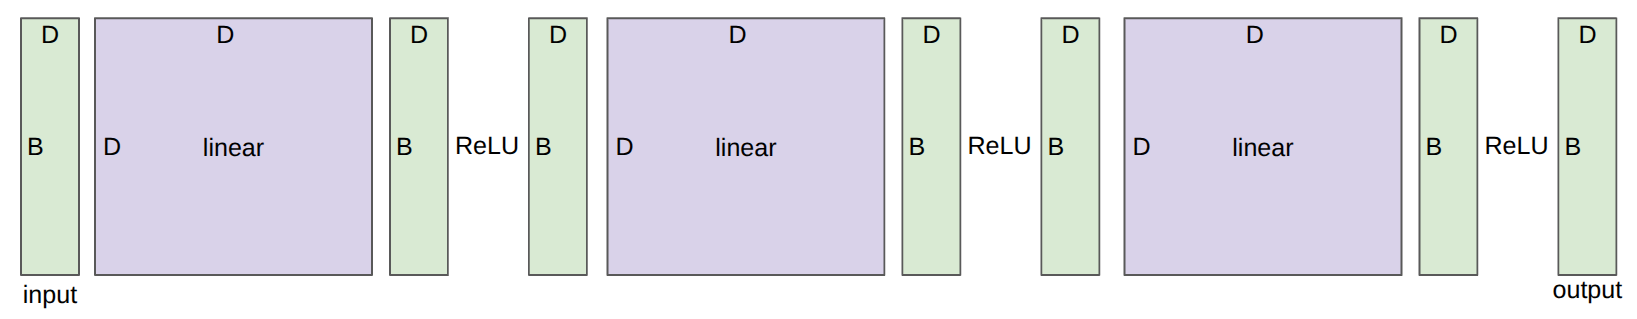

**记录步骤 964 · activation_checkpointing · L754**

```python
text("The memory usage is")
```

The memory usage is

**记录步骤 965 · activation_checkpointing · L755**

```python
B = 64     # Batch size
```

**记录步骤 966 · activation_checkpointing · L756**

```python
L = 16     # Number of layers
```

**记录步骤 967 · activation_checkpointing · L757**

```python
D = 1024   # Dimensionality
```

**记录步骤 968 · activation_checkpointing · L759**

```python
x = torch.randn(B, D, device=cuda_if_available())
```

**记录步骤 969 · activation_checkpointing · L760**

```python
activation_memory = B * D * 2 * L  # @inspect activation_memory
```

原课堂变量快照：
```json
{
  "activation_memory": {
    "type": "int",
    "contents": 2097152,
    "dtype": null,
    "shape": null
  }
}
```

**记录步骤 970 · activation_checkpointing · L762**

```python
model = DeepNetwork(dim=D, num_layers=L).to(cuda_if_available())  # @stepover
```

**记录步骤 971 · activation_checkpointing · L763**

```python
memory = get_max_memory_usage(lambda: model(x).backward())  # @inspect memory @stepover
```

原课堂变量快照：
```json
{
  "memory": {
    "type": "int",
    "contents": 0,
    "dtype": null,
    "shape": null
  }
}
```

**记录步骤 972 · activation_checkpointing · L765**

```python
text("Can we reduce this?")
```

Can we reduce this?

**记录步骤 973 · activation_checkpointing · L767**

```python
text("Activation checkpointing = gradient checkpointing = rematerialization")
```

Activation checkpointing = gradient checkpointing = rematerialization

**记录步骤 974 · activation_checkpointing · L768**

```python
text("Key idea:")
```

Key idea:

**记录步骤 975 · activation_checkpointing · L769**

```python
text("- Forward pass: keep only activations at subset of layers")
```

- Forward pass: keep only activations at subset of layers

**记录步骤 976 · activation_checkpointing · L770**

```python
text("- Backward pass: recompute the missing activations from the last checkpoint")
```

- Backward pass: recompute the missing activations from the last checkpoint

**记录步骤 977 · activation_checkpointing · L771**

```python
text("Philosophy: tradeoff memory for compute")
```

Philosophy: tradeoff memory for compute

**记录步骤 978 · activation_checkpointing · L777**

```python
model = DeepNetworkCheckpointed(dim=D, num_layers=L).to(cuda_if_available())  # @stepover
```

**记录步骤 979 · activation_checkpointing · L778**

```python
checkpointed_memory = get_max_memory_usage(lambda: model(x).backward())  # @inspect checkpointed_memory @stepover
```

原课堂变量快照：
```json
{
  "checkpointed_memory": {
    "type": "int",
    "contents": 0,
    "dtype": null,
    "shape": null
  }
}
```

**记录步骤 980 · activation_checkpointing · L780**

```python
text("Can we reduce this even more, especially for deep networks (large L)?")
```

Can we reduce this even more, especially for deep networks (large L)?

**记录步骤 981 · activation_checkpointing · L786**

```python
text("How frequently to checkpoint?")
```

How frequently to checkpoint?

**记录步骤 982 · activation_checkpointing · L787**

```python
text("- If store each layer's activations, then activation memory is O(L) and no recomputation.")
```

- If store each layer's activations, then activation memory is O(L) and no recomputation.

**记录步骤 983 · activation_checkpointing · L788**

```python
text("- If store no activations, then activation memory is O(1) and compute is O(L^2) (recompute from the start for each layer).")
```

- If store no activations, then activation memory is O(1) and compute is O(L^2) (recompute from the start for each layer).

**记录步骤 984 · activation_checkpointing · L789**

```python
text("- If store every sqrt(L) layers, then activation memory is O(sqrt(L)) and O(sqrt(L)) recomputation, balanced.")
```

- If store every sqrt(L) layers, then activation memory is O(sqrt(L)) and O(sqrt(L)) recomputation, balanced.

## main

**记录步骤 985 · main · L60**

```python
activation_checkpointing()
```

**记录步骤 986 · main · L62**

```python
text("Summary:")
```

Summary:

**记录步骤 987 · main · L63**

```python
text("- Everything is operations on tensors (parameters, gradients, activations, optimizer states, data)")
```

- Everything is operations on tensors (parameters, gradients, activations, optimizer states, data)

**记录步骤 988 · main · L64**

```python
text("- einops: better way to think about tensor operations")
```

- einops: better way to think about tensor operations

**记录步骤 989 · main · L65**

```python
text("- 6 (# data points) (# parameters) FLOPs per training step")
```

- 6 (# data points) (# parameters) FLOPs per training step

**记录步骤 990 · main · L66**

```python
text("- Arithmetic intensity / roofline analysis: compute-bound or memory-bound?")
```

- Arithmetic intensity / roofline analysis: compute-bound or memory-bound?

**记录步骤 991 · main · L67**

```python
text("- Matrix multiplications are compute-bound, elementwise operations are memory-bound")
```

- Matrix multiplications are compute-bound, elementwise operations are memory-bound

**记录步骤 992 · main · L68**

```python
text("- Gradient accumulation, activation checkpointing: reduce memory to use bigger batch sizes")
```

- Gradient accumulation, activation checkpointing: reduce memory to use bigger batch sizes